# Ranking pipeline diagnostic analysis

Development-only, exploratory analysis of numerical interests, natural-language evidence, benchmark suitability, and retrieval/fusion failures. This notebook uses the frozen seven M4 runs as a compatible comparison set, with original M2/M3 history retained. It does **not** implement a new ranker, tune on held-out profiles, or register diagnostic calculations as experiments.

Run all cells from the repository root using the project environment. Install `requirements-diagnostics.txt` first. The saved notebook contains executed tables, charts, and computed interpretations. CSVs, standalone chart PNGs, annotation templates, and a computed findings summary are written only under `reports/ranking/diagnostics/`.

The central comparison is privileged synthetic **oracle RIASEC** versus opening-text retrieval, not extractor/tracker performance. Exact-target labels and O*NET relatedness are benchmark labels, not verified human career suitability. Specificity and failure classifications are provisional unless reviewed by a human.

The executive summary and final recommendations below are generated from actual values. Subgroup associations, proxy thresholds, and correlations are exploratory; none establish causation.


In [1]:
from pathlib import Path
import os, sys, json, re, hashlib
ROOT = Path.cwd()
assert (ROOT / "data/dev_profiles.jsonl").is_file(), "Run the notebook with the repository root as working directory."
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".venv/matplotlib-cache"))
sys.path.insert(0, str(ROOT))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from notebooks.ranking_diagnostics import *
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 20)
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(exist_ok=True)
before = protected_fingerprints()
findings = []

def conclude(section, finding, interpretation, limitation, experiment):
    findings.append({"section": section, "finding": finding, "interpretation": interpretation,
                     "limitation": limitation, "next_experiment": experiment})
    display(Markdown(f"**Finding:** {finding}\n\n**Interpretation:** {interpretation}\n\n**Limitation:** {limitation}\n\n**Next experiment:** {experiment}"))

def chart(title, xlabel=None, ylabel=None):
    ax = plt.gca()
    ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    plt.tight_layout()
    filename = re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_")
    plt.gcf().savefig(OUT / "figures" / (filename + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

def scatter(x, y, title, xlabel, ylabel, log_rank=False):
    plt.figure()
    plt.scatter(x, y, alpha=.7, s=30)
    if log_rank: plt.yscale("log")
    chart(title, xlabel, ylabel)

def rank_for_plot(series):
    # Display-only sentinel; exported ranks and evaluator metrics retain missingness.
    return series.fillna(len(occupation) + 1)

def group_chart(attribute, metric="hit_at_5", methods=("m1", "m3", "m4", "fusion")):
    values = subgroup_metrics(long, attribute)
    groups = list(dict.fromkeys(values.group))
    x = np.arange(len(groups))
    width = .8 / len(methods)
    plt.figure(figsize=(max(8, len(groups) * 1.3), 4.5))
    counts = {}
    for i, method in enumerate(methods):
        part = values[(values.method == method) & (values.metric == metric)].set_index("group").reindex(groups)
        counts.update(part.n.to_dict())
        errors = np.maximum(0, np.array([part["mean"] - part.ci_low, part.ci_high - part["mean"]]))
        plt.bar(x + (i - (len(methods)-1)/2)*width, part["mean"], width, label=NAMES[method], yerr=errors, capsize=2)
    plt.xticks(x, [f"{g}\n(n={int(counts[g])})" for g in groups], rotation=20, ha="right")
    plt.legend(fontsize=8)
    chart(f"{metric} by {attribute}: exploratory bootstrap intervals", attribute, metric)

## Data loading and validation

**Research question:** Are these artifacts safe to join?

**Hypothesis:** The seven M4 runs share fixed requests, labels, pool and evaluator definitions.

**Data and methodology:** Validate hashes, profile sets, input snapshots, variants, finite numerical data and all six metrics using the existing evaluator. Invalid/missing targets are reported, never dropped.

In [2]:
profiles, occupation, catalog, manifests, predictions, metrics, grade_rows, integrity = load_analysis()
display(pd.Series(integrity, name="count").to_frame())
vectors = pd.DataFrame([{t: p["hidden_slots"][t] for t in TYPES} for p in profiles], index=[p["id"] for p in profiles])
diag, lexical = make_profile_table(profiles, occupation, predictions)
semantic_live, sentence_matches, semantic_status = semantic_diagnostics(profiles, occupation, diag, manifests)
if not semantic_live.empty:
    diag = diag.merge(semantic_live, on="profile_id", validate="one_to_one")
else:
    for column in ("target_task_count", "distinct_winning_tasks", "dominant_task_share", "target_sentence_max_spread", "best_task_minus_aggregate", "competitor_dominant_task_share"):
        diag[column] = np.nan
display(Markdown(semantic_status))
diag["length_bin"] = pd.qcut(diag.word_count, 3, duplicates="drop").astype(str)
diag["ambiguity_group"] = np.where(diag.has_twins, "listed twins", np.where(diag.score_band_count >= 5, "score-band crowding only", "neither proxy"))
diag["has_negative_cue"] = diag.text.str.contains(r"\b(?:dislike|hate|not|never)\b|don't|isn't|can't", case=False, regex=True)
diag["domain_detail_proxy"] = np.where(diag.domain_cue_count >= 2, "2+ domain cues", "0-1 domain cues")
long = metrics.merge(diag, on="profile_id", validate="many_to_one")
overview = metrics.groupby("method", sort=False)[list(METRICS)].mean().reindex(RUNS)
rank_wide = diag.set_index("profile_id")[[f"{m}_target_rank" for m in RUNS]]
metric_wide = metrics.pivot(index="profile_id", columns="method", values=["hit_at_5", "ndcg_at_10"])
display(pd.DataFrame({"method": list(RUNS), "report": [f"reports/ranking/m4/{v}" for v in RUNS.values()],
                      "run_id": [manifests[m]["run_id"] for m in RUNS]}))
conclude("Integrity", f"{len(diag)} profiles and {len(occupation)} eligible occupations; {integrity['excluded_profiles']} profiles excluded. All seven saved metric sets reproduce with the existing evaluator.",
         "Only matching development/oracle requests and recognized baseline variants are compared. Missing lexical retrieval remains an unavailable rank, not a zero rank.",
         "Dataset/profile validity is not a verification of synthetic labels or human relevance. Auxiliary task/model fingerprints are checked separately from shared evaluation data.",
         "Keep these integrity checks when introducing future configurations.")

,count
profiles,60
unique_ids,60
eligible_occupations,378
missing_targets,0
ineligible_targets,0
unknown_related_codes,0
related_codes_outside_pool,271
nonfinite_or_missing_riasec,0
missing_text,0
excluded_profiles,0


C:\Users\aanny\Documents\GitHub\year5\cs425\project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7957.80it/s]

Actual pinned model/cache reused; task embeddings were not rebuilt.

,method,report,run_id
0,m1,reports/ranking/m4/structured,m2_structured_oracle_dev_v1_a630e17a163f453e8a127fe5505aeace
1,m3,reports/ranking/m4/bm25,m2_structured_oracle_dev_v1_5f539bef857e475fa8c8b51a4e4220a9
2,m4,reports/ranking/m4/dense,m2_structured_oracle_dev_v1_baea7160e7a14f6dbe3b8cc7f908a40d
3,m1_m3,reports/ranking/m4/hybrid,m2_structured_oracle_dev_v1_bdbb8880ef3342cbb0c7d8422a9878a9
4,m1_m4,reports/ranking/m4/structured_dense,m2_structured_oracle_dev_v1_0c582c01d043498199e4b44f38821020
5,m3_m4,reports/ranking/m4/bm25_dense,m2_structured_oracle_dev_v1_50c5c23e6bd14ec38eaeff5f27a8e8bb
6,fusion,reports/ranking/m4/three_way,m2_structured_oracle_dev_v1_72def54147574fb8bfaed4e536a78fda


**Finding:** 60 profiles and 378 eligible occupations; 0 profiles excluded. All seven saved metric sets reproduce with the existing evaluator.

**Interpretation:** Only matching development/oracle requests and recognized baseline variants are compared. Missing lexical retrieval remains an unavailable rank, not a zero rank.

**Limitation:** Dataset/profile validity is not a verification of synthetic labels or human relevance. Auxiliary task/model fingerprints are checked separately from shared evaluation data.

**Next experiment:** Keep these integrity checks when introducing future configurations.

## Baseline performance and executive summary

**Research question:** What actually differs across methods?

**Hypothesis:** Text signals may add useful cases while reducing aggregate oracle accuracy.

**Data and methodology:** All seven configurations, paired profile bootstrap differences (2,000 resamples, seed 425), unchanged M2 metrics.

,hit_at_1,hit_at_5,hit_at_10,mrr,ndcg_at_5,ndcg_at_10
method,,,,,,
M1,0.0333,0.1667,0.4333,0.1356,0.1515,0.2035
BM25,0.0000,0.0167,0.0333,0.0161,0.0142,0.0205
MiniLM,0.0000,0.0500,0.0500,0.0255,0.0289,0.0314
M1+BM25,0.0167,0.1333,0.2000,0.0849,0.0981,0.1166
M1+MiniLM,0.0167,0.1167,0.2000,0.0866,0.1035,0.1216
BM25+MiniLM,0.0000,0.0333,0.0500,0.0238,0.0187,0.0237
Three-way RRF,0.0000,0.0500,0.1167,0.0452,0.0513,0.0685


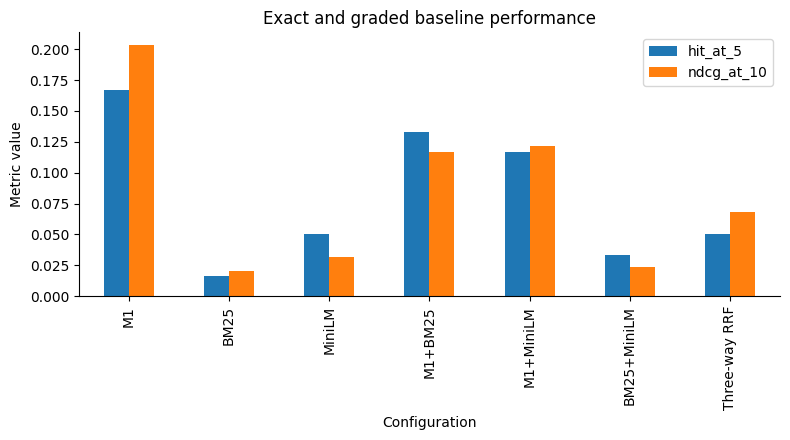

,method,metric,mean_difference,ci_low,ci_high,improved,regressed,n
0,m3,hit_at_5,-0.1500,-0.2500,-0.0500,1,10,60
1,m3,mrr,-0.1195,-0.1725,-0.0744,4,56,60
2,m3,ndcg_at_10,-0.1829,-0.2335,-0.1298,5,47,60
3,m4,hit_at_5,-0.1167,-0.2171,0.0000,3,10,60
4,m4,mrr,-0.1101,-0.1678,-0.0587,4,55,60
5,m4,ndcg_at_10,-0.1720,-0.2240,-0.1172,5,47,60
6,m1_m3,hit_at_5,-0.0333,-0.1333,0.0833,5,7,60
7,m1_m3,mrr,-0.0507,-0.1076,0.0094,11,48,60
8,m1_m3,ndcg_at_10,-0.0869,-0.1369,-0.0363,21,34,60
9,m1_m4,hit_at_5,-0.0500,-0.1667,0.0667,5,8,60


**Computed executive summary:** M1 Hit@5 is 16.7%; BM25 1.7%; MiniLM 5.0%; three-way RRF 5.0%. All results use 60 identical development requests. The following sections separate numerical ambiguity, text evidence and fusion behaviour.

**Finding:** Three-way RRF changes Hit@5 by -11.7 percentage points compared with M1.

**Interpretation:** A new retrieval signal is not automatically complementary to an oracle profile. Inspect paired cases rather than interpreting aggregate loss as a single cause.

**Limitation:** This is a small synthetic development benchmark; oracle and text channels have different information access.

**Next experiment:** Audit evidence and benchmark identifiability before optimizing components.

In [3]:
display(overview.rename(index=NAMES).round(4))
overview[["hit_at_5", "ndcg_at_10"]].rename(index=NAMES).plot.bar()
chart("Exact and graded baseline performance", "Configuration", "Metric value")
paired = []
for method in RUNS:
    if method == "m1": continue
    for metric in ("hit_at_5", "mrr", "ndcg_at_10"):
        a = metrics[metrics.method == "m1"].set_index("profile_id")[metric]
        b = metrics[metrics.method == method].set_index("profile_id")[metric]
        delta = b-a
        low, high = interval(delta)
        paired.append({"method": method, "metric": metric, "mean_difference": delta.mean(), "ci_low": low, "ci_high": high,
                       "improved": int((delta > 0).sum()), "regressed": int((delta < 0).sum()), "n": len(delta)})
paired = pd.DataFrame(paired)
display(paired.round(4))
display(Markdown(f"**Computed executive summary:** M1 Hit@5 is {overview.loc['m1','hit_at_5']:.1%}; BM25 {overview.loc['m3','hit_at_5']:.1%}; MiniLM {overview.loc['m4','hit_at_5']:.1%}; three-way RRF {overview.loc['fusion','hit_at_5']:.1%}. All results use {len(diag)} identical development requests. The following sections separate numerical ambiguity, text evidence and fusion behaviour."))
conclude("Overview", f"Three-way RRF changes Hit@5 by {100*(overview.loc['fusion','hit_at_5']-overview.loc['m1','hit_at_5']):+.1f} percentage points compared with M1.",
         "A new retrieval signal is not automatically complementary to an oracle profile. Inspect paired cases rather than interpreting aggregate loss as a single cause.",
         "This is a small synthetic development benchmark; oracle and text channels have different information access.", "Audit evidence and benchmark identifiability before optimizing components.")

## A1 - RIASEC distributions

**Research question:** Are some numerical interests disproportionately represented?

**Hypothesis:** Target sampling and synthetic construction may create imbalanced dimensions and correlations.

**Data and methodology:** Summaries, polarity proportions, fixed-order argmax counts, and Pearson correlations of unbounded synthetic z-scale hidden_slots. Ties use R,I,A,S,E,C order and are counted explicitly.

,count,mean,std,min,25%,50%,75%,max,positive_share,negative_share,zero_share
R,60.0,-0.565333,0.924678,-2.63,-1.2825,-0.525,0.1450,1.10,0.316667,0.683333,0.0
I,60.0,0.713333,0.849751,-1.07,0.1550,0.810,1.2900,2.60,0.783333,0.216667,0.0
A,60.0,0.134167,0.845840,-1.19,-0.4125,-0.070,0.4100,2.30,0.466667,0.533333,0.0
S,60.0,0.408167,0.984727,-1.49,-0.3600,0.250,1.1625,2.36,0.583333,0.416667,0.0
E,60.0,0.497833,1.174753,-1.57,-0.3650,0.280,1.4475,2.98,0.566667,0.433333,0.0
C,60.0,0.016167,0.981878,-1.88,-0.6825,0.040,0.7950,2.03,0.516667,0.483333,0.0


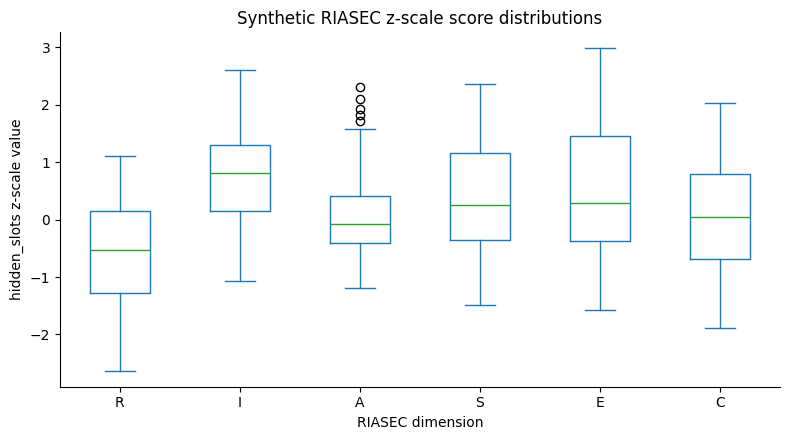

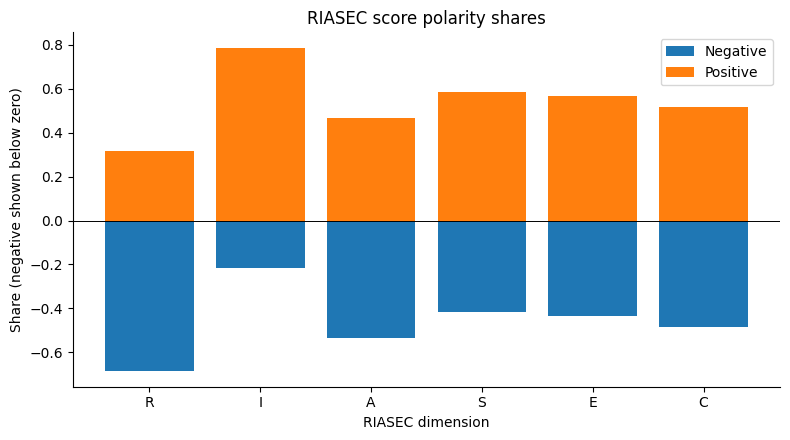

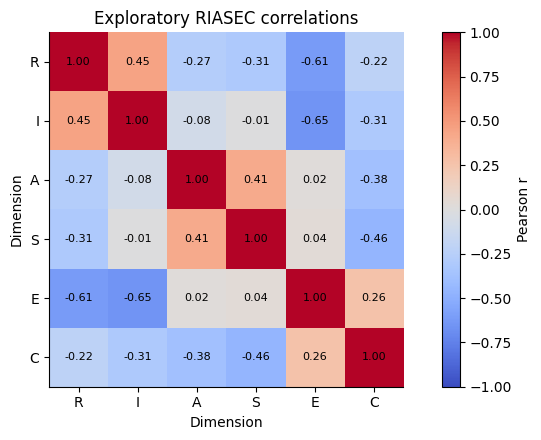

,strongest absolute,dominant positive
R,6,1
I,13,20
A,7,5
S,13,12
E,15,18
C,6,4


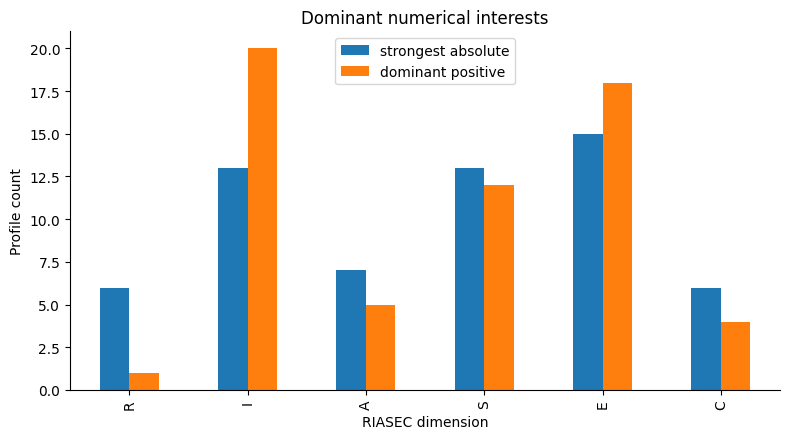

**Finding:** I is the most frequent dominant positive dimension (20/60 profiles); 1 absolute-dominance ties. Scores range from -2.63 to 2.98.

**Interpretation:** The sample is not a uniform six-type population; polarity and correlations characterize the benchmark's numerical signal.

**Limitation:** Observed imbalance does not establish that it causes retrieval failures; dimensions are not independent occupations.

**Next experiment:** Use fixed stratified subsets and report dominant-type sample sizes in future experiments.

In [4]:
distribution = vectors.describe().T
distribution["positive_share"] = (vectors > 0).mean()
distribution["negative_share"] = (vectors < 0).mean()
distribution["zero_share"] = (vectors == 0).mean()
display(distribution)
vectors.plot.box()
chart("Synthetic RIASEC z-scale score distributions", "RIASEC dimension", "hidden_slots z-scale value")
plt.figure()
plt.bar(TYPES, -(vectors < 0).mean(), label="Negative")
plt.bar(TYPES, (vectors > 0).mean(), label="Positive")
plt.axhline(0, color="black", lw=.7); plt.legend()
chart("RIASEC score polarity shares", "RIASEC dimension", "Share (negative shown below zero)")
plt.figure(); plt.imshow(vectors.corr(), vmin=-1, vmax=1, cmap="coolwarm"); plt.colorbar(label="Pearson r")
plt.xticks(range(6), TYPES); plt.yticks(range(6), TYPES)
for i in range(6):
    for j in range(6): plt.text(j, i, f"{vectors.corr().iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
chart("Exploratory RIASEC correlations", "Dimension", "Dimension")
dominance = pd.DataFrame({"strongest absolute": diag.dominant_absolute.value_counts(), "dominant positive": diag.dominant_positive.value_counts()}).reindex(TYPES).fillna(0)
display(dominance.astype(int)); dominance.plot.bar()
chart("Dominant numerical interests", "RIASEC dimension", "Profile count")
ties = int(vectors.abs().eq(vectors.abs().max(axis=1), axis=0).sum(axis=1).gt(1).sum())
most = dominance['dominant positive'].idxmax()
conclude("A1", f"{most} is the most frequent dominant positive dimension ({int(dominance.loc[most,'dominant positive'])}/{len(diag)} profiles); {ties} absolute-dominance ties. Scores range from {vectors.min().min():.2f} to {vectors.max().max():.2f}.",
         "The sample is not a uniform six-type population; polarity and correlations characterize the benchmark's numerical signal.",
         "Observed imbalance does not establish that it causes retrieval failures; dimensions are not independent occupations.", "Use fixed stratified subsets and report dominant-type sample sizes in future experiments.")

## A2 - User-target numerical alignment

**Research question:** Can aligned numerical vectors still miss the target?

**Hypothesis:** Dot-product competition, vector magnitude and related occupation profiles can produce misses even at high cosine alignment.

**Data and methodology:** Recompute production M1 exactly; compare target_profile to actual O*NET vectors within 0.0050001 rounding tolerance, cosine as a diagnostic only, scores and full-pool ranks.

,target_cosine,user_target_l2,target_profile_max_abs_difference,m1_target_score,m1_best_competitor_score,m1_target_rank,target_vector_norm,m1_winner_norm
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,0.950286,0.737830,0.004277,6.267832,7.804961,25.550000,2.435497,3.429075
std,0.044685,0.222817,0.000713,3.318528,3.502145,26.136814,0.655997,0.688112
min,0.807656,0.244345,0.001594,0.849534,1.575313,1.000000,1.141301,1.761584
25%,0.929746,0.638816,0.003995,3.651880,5.087991,7.000000,1.900944,2.888656
50%,0.960049,0.732920,0.004526,5.591399,7.531069,16.000000,2.393653,3.388794
75%,0.986538,0.907446,0.004732,8.852635,9.944567,32.250000,2.997883,3.800115
max,0.998481,1.248989,0.004981,13.969123,16.133309,103.000000,3.546647,4.666245


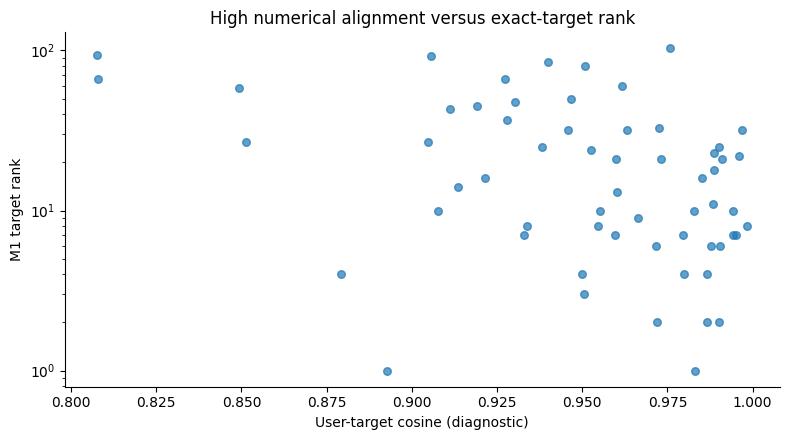

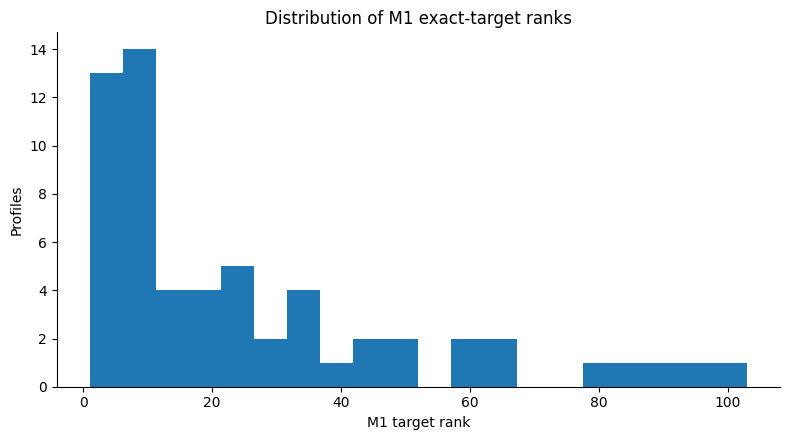

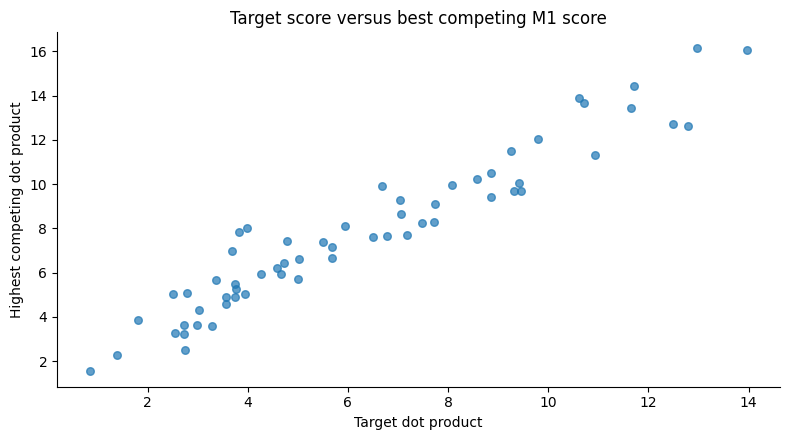

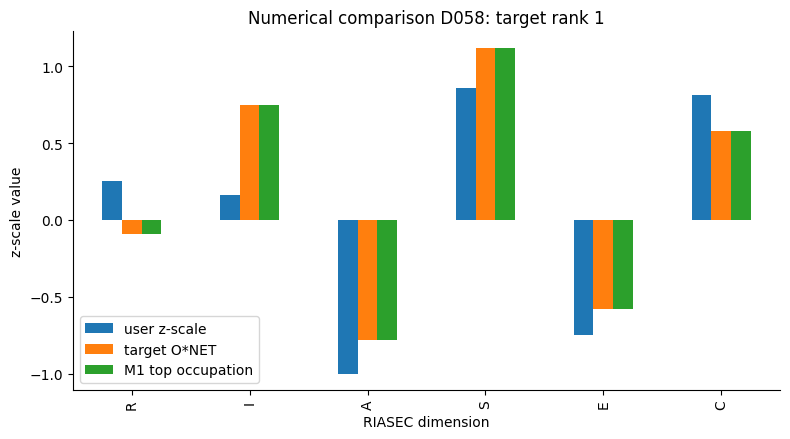

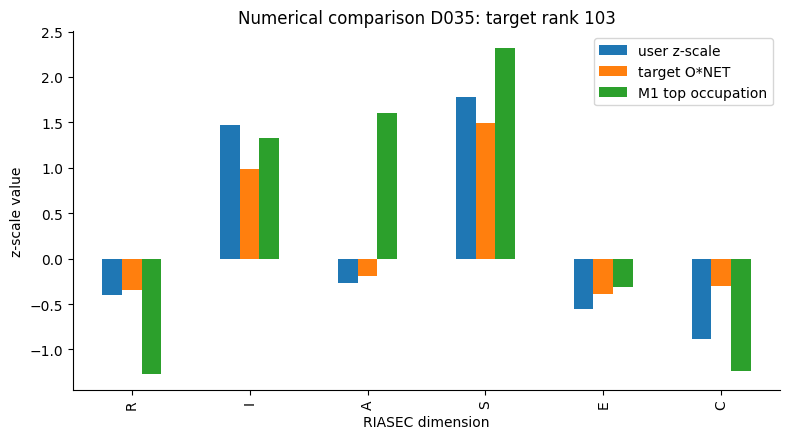

**Finding:** 60/60 target_profile vectors agree with O*NET within two-decimal rounding. Median cosine is 0.960; 30/37 profiles with cosine >= .95 still miss M1 top five.

**Interpretation:** Close direction alignment is insufficient for a dot-product winner. Dot products depend on vector norms as well as angle, and the full pool supplies competing vectors.

**Limitation:** A cosine plot is an analytical diagnostic, not evidence for adopting a new scoring formula. Synthetic targets are not a unique career ground truth.

**Next experiment:** If justified, preregister a separate structured-scoring comparison with frozen inputs; do not change M1 here.

In [5]:
agreement = int(diag.target_profile_max_abs_difference.le(.0050001).sum())
display(diag[["profile_id","target_cosine","user_target_l2","target_profile_max_abs_difference","m1_target_score","m1_best_competitor_score","m1_target_rank","target_vector_norm","m1_winner_norm"]].describe())
scatter(diag.target_cosine, diag.m1_target_rank, "High numerical alignment versus exact-target rank", "User-target cosine (diagnostic)", "M1 target rank", True)
plt.figure(); plt.hist(diag.m1_target_rank, bins=20)
chart("Distribution of M1 exact-target ranks", "M1 target rank", "Profiles")
scatter(diag.m1_target_score, diag.m1_best_competitor_score, "Target score versus best competing M1 score", "Target dot product", "Highest competing dot product")
examples = diag.sort_values("m1_target_rank").iloc[[0,-1]].profile_id.tolist()
pmap = {p['id']: p for p in profiles}
for pid in examples:
    p = pmap[pid]
    winner = predictions['m1'][pid][0]['code']
    frame = pd.DataFrame({'user z-scale': p['hidden_slots'], 'target O*NET': occupation[p['target']].z_scores, 'M1 top occupation': occupation[winner].z_scores}).reindex(TYPES)
    frame.plot.bar(); chart(f"Numerical comparison {pid}: target rank {int(diag.set_index('profile_id').loc[pid,'m1_target_rank'])}", "RIASEC dimension", "z-scale value")
high = diag.target_cosine.ge(.95)
conclude("A2", f"{agreement}/{len(diag)} target_profile vectors agree with O*NET within two-decimal rounding. Median cosine is {diag.target_cosine.median():.3f}; {int((high & diag.m1_target_rank.gt(5)).sum())}/{int(high.sum())} profiles with cosine >= .95 still miss M1 top five.",
         "Close direction alignment is insufficient for a dot-product winner. Dot products depend on vector norms as well as angle, and the full pool supplies competing vectors.",
         "A cosine plot is an analytical diagnostic, not evidence for adopting a new scoring formula. Synthetic targets are not a unique career ground truth.", "If justified, preregister a separate structured-scoring comparison with frozen inputs; do not change M1 here.")

## A3 - RIASEC ambiguity and twins

**Research question:** Do similar occupation profiles explain exact-target difficulty?

**Hypothesis:** Listed twins and crowded score neighbourhoods may make structured ranking ambiguous, but text may or may not resolve them.

**Data and methodology:** Dataset riasec_twins stay separate from calculated cosine >= .99 neighbours and an exploratory +/-0.1 target-score band. Compare paired metrics with and without listed twins.

,riasec_twin_count,calculated_cosine_neighbors,score_band_count,target_rank_within_score_band,m1_margin
count,60.000000,60.000000,60.000000,60.000000,60.000000
mean,1.516667,0.550000,6.833333,3.816667,-1.537129
std,2.606977,1.185005,6.373054,3.175604,0.995146
min,0.000000,0.000000,1.000000,1.000000,-4.055062
25%,0.000000,0.000000,2.000000,1.000000,-2.169089
50%,0.000000,0.000000,5.000000,3.000000,-1.484722
75%,2.000000,1.000000,9.000000,5.000000,-0.738478
max,13.000000,6.000000,34.000000,16.000000,0.230585


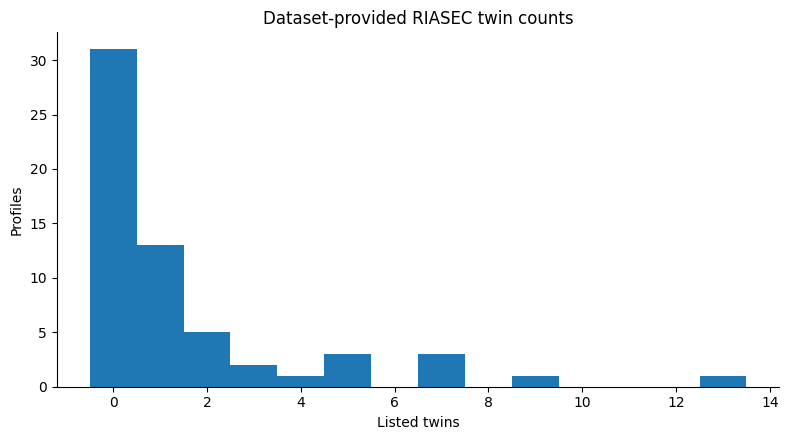

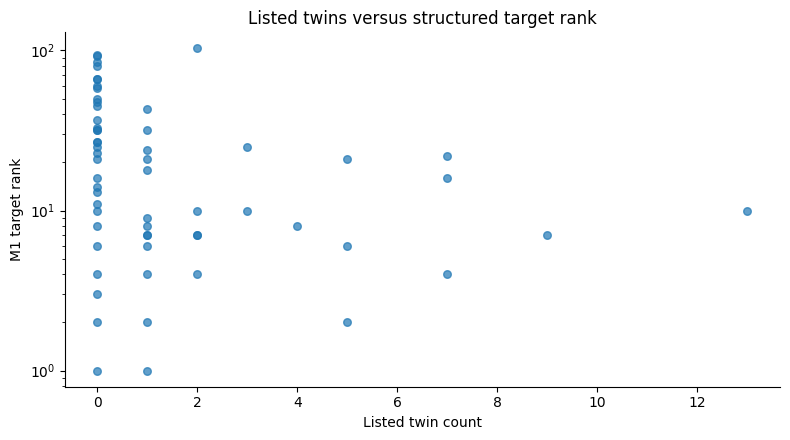

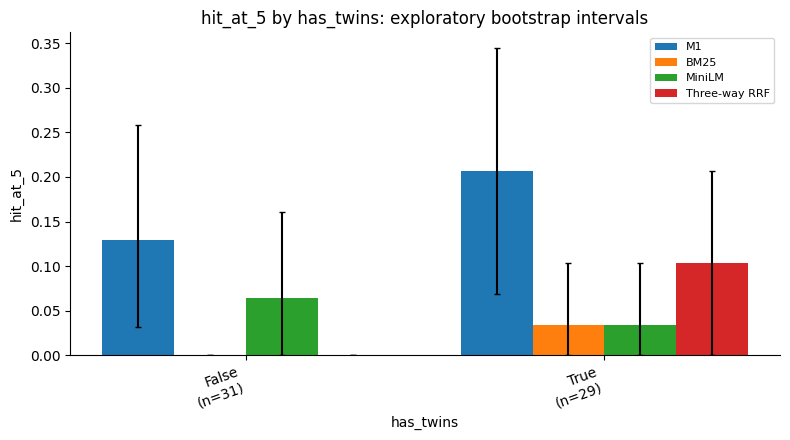

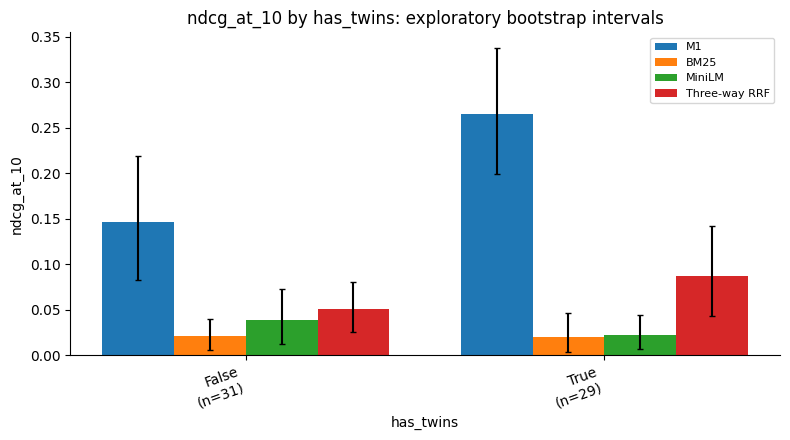

,profile_id,code,is_target,score,rank
0,D020,19-1013.00,False,1.575313,1
1,D020,19-2031.00,False,1.527657,2
2,D020,19-2032.00,False,1.525216,3
3,D020,17-2112.03,True,0.849534,66
4,D030,19-2031.00,False,2.289913,1
5,D030,19-1011.00,False,2.252555,2
6,D030,19-1013.00,False,2.172175,3
7,D030,19-1032.00,True,1.382861,58
8,D034,29-1229.04,False,3.863475,1
9,D034,29-1229.03,False,3.813028,2


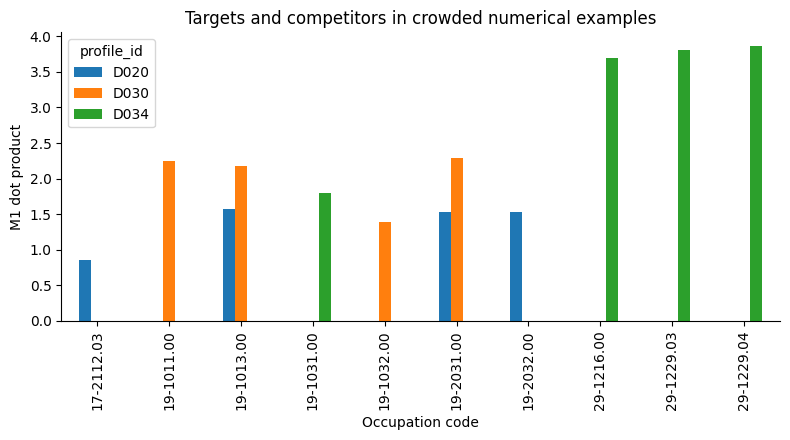

**Finding:** 29/60 profiles list twins; median score-band occupancy is 5.0, excluding no profiles.

**Interpretation:** Provided twins, cosine neighbours and close score bands describe different forms of ambiguity. Subgroup metrics show whether retrieval adds labeled relevance in each group.

**Limitation:** The .99 cosine and +/-0.1 score thresholds are exploratory descriptors, not accepted occupation-equivalence definitions.

**Next experiment:** Test text disambiguation on reviewed ambiguous cases with the same numerical profile and candidate pool.

In [6]:
display(diag[["riasec_twin_count","calculated_cosine_neighbors","score_band_count","target_rank_within_score_band","m1_margin"]].describe())
plt.figure(); plt.hist(diag.riasec_twin_count, bins=np.arange(diag.riasec_twin_count.max()+2)-.5)
chart("Dataset-provided RIASEC twin counts", "Listed twins", "Profiles")
scatter(diag.riasec_twin_count, diag.m1_target_rank, "Listed twins versus structured target rank", "Listed twin count", "M1 target rank", True)
group_chart("has_twins"); group_chart("has_twins", "ndcg_at_10")
selected = diag.sort_values("score_band_count", ascending=False).head(3).profile_id
comparison = []
for pid in selected:
    target = diag.set_index('profile_id').loc[pid,'target_code']
    candidates = predictions['m1'][pid][:3] + [r for r in predictions['m1'][pid] if r['code']==target]
    comparison.extend({'profile_id': pid, 'code': r['code'], 'is_target': r['code']==target, 'score': r['signals']['structured']['score'], 'rank': r['rank']} for r in candidates)
display(pd.DataFrame(comparison).drop_duplicates())
pd.DataFrame(comparison).drop_duplicates().pivot(index='code', columns='profile_id', values='score').plot.bar()
chart("Targets and competitors in crowded numerical examples", "Occupation code", "M1 dot product")
conclude("A3", f"{int(diag.has_twins.sum())}/{len(diag)} profiles list twins; median score-band occupancy is {diag.score_band_count.median():.1f}, excluding no profiles.",
         "Provided twins, cosine neighbours and close score bands describe different forms of ambiguity. Subgroup metrics show whether retrieval adds labeled relevance in each group.",
         "The .99 cosine and +/-0.1 score thresholds are exploratory descriptors, not accepted occupation-equivalence definitions.", "Test text disambiguation on reviewed ambiguous cases with the same numerical profile and candidate pool.")

## B1 - Text length, structure and complexity

**Research question:** Is retrieval performance associated with text quantity or style?

**Hypothesis:** More text can add useful information or distracting material rather than monotonically improving retrieval.

**Data and methodology:** Word/character/sentence counts, unique tokens, lexical diversity and available metadata; equal-frequency length bins, subgroup sizes and exploratory rank correlations.

,word_count,character_count,sentence_count,unique_token_count,lexical_diversity
count,60.000000,60.000000,60.000000,60.000000,60.000000
mean,61.583333,352.216667,4.066667,51.216667,0.848854
std,20.294686,118.684040,1.325968,15.054806,0.068171
min,19.000000,101.000000,1.000000,19.000000,0.723404
25%,51.250000,291.750000,4.000000,42.750000,0.792011
50%,66.500000,378.000000,4.000000,55.000000,0.845486
75%,75.250000,429.500000,5.000000,61.500000,0.877080
max,103.000000,587.000000,6.000000,78.000000,1.000000


hit_at_5       ndcg_at_10      
                       mean count       mean count
text_style method                                 
full       fusion  0.041667    48   0.072190    48
           m1      0.187500    48   0.224699    48
           m1_m3   0.145833    48   0.130431    48
           m1_m4   0.104167    48   0.131092    48
           m3      0.000000    48   0.018568    48
           m3_m4   0.020833    48   0.020290    48
           m4      0.041667    48   0.034909    48
messy      fusion  0.083333    12   0.053782    12
           m1      0.083333    12   0.118560    12
           m1_m3   0.083333    12   0.061328    12
           m1_m4   0.166667    12   0.083833    12
           m3      0.083333    12   0.028448    12
           m3_m4   0.083333    12   0.037536    12
           m4      0.083333    12   0.017581    12

hit_at_5       ndcg_at_10      
                             mean count       mean count
length_bin       method                                 
(18.999, 59.333] fusion  0.050000    20   0.055498    20
                 m1      0.100000    20   0.139847    20
                 m1_m3   0.100000    20   0.101449    20
                 m1_m4   0.100000    20   0.103746    20
                 m3      0.050000    20   0.031555    20
...                           ...   ...        ...   ...
(72.0, 103.0]    m1_m3   0.055556    18   0.089552    18
                 m1_m4   0.111111    18   0.129738    18
                 m3      0.000000    18   0.010143    18
                 m3_m4   0.000000    18   0.015610    18
                 m4      0.000000    18   0.018716    18

[21 rows x 4 columns]

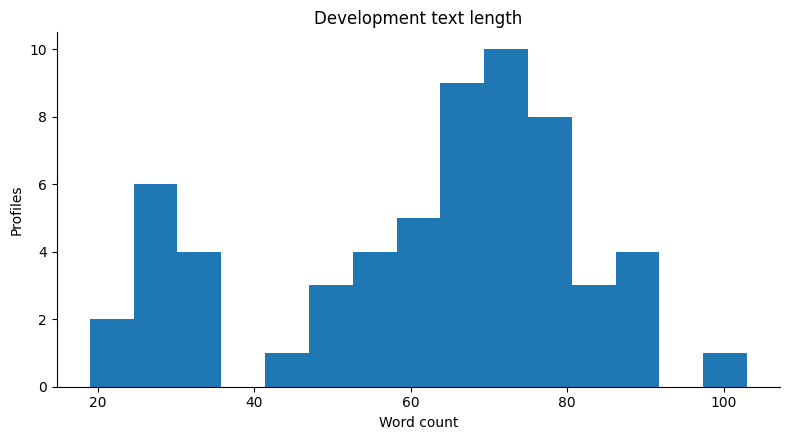

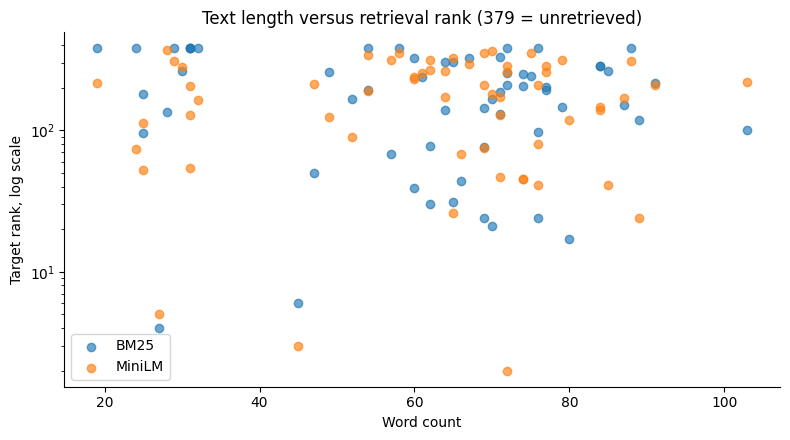

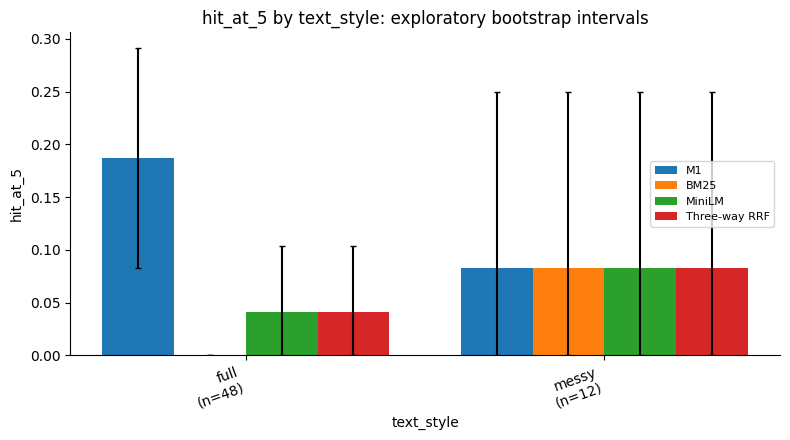

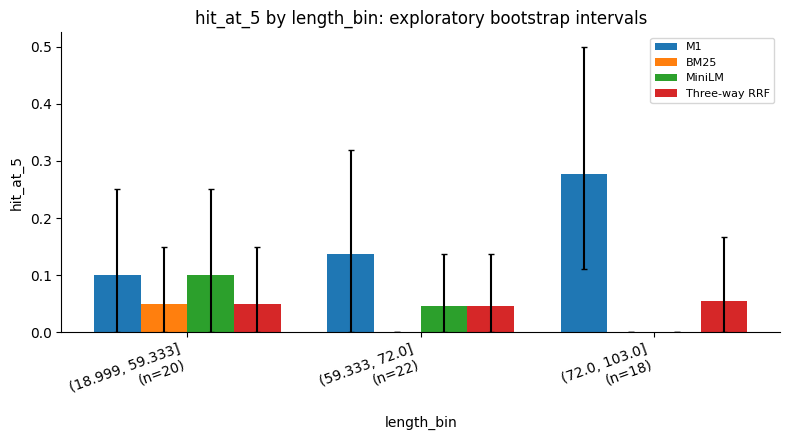

,word_count,sentence_count,lexical_diversity,m3_target_rank,m4_target_rank
word_count,1.000000,0.658895,-0.675072,0.179135,-0.034833
sentence_count,0.658895,1.000000,-0.724731,0.079050,-0.017936
lexical_diversity,-0.675072,-0.724731,1.000000,-0.019190,-0.017135
m3_target_rank,0.179135,0.079050,-0.019190,1.000000,0.194533
m4_target_rank,-0.034833,-0.017936,-0.017135,0.194533,1.000000


**Finding:** Median length is 66 words and 4 sentences; style counts are {'full': 48, 'messy': 12}.

**Interpretation:** Length and style associations describe this benchmark. Subgroup error bars are profile-bootstrap intervals; longer text can contain both preferences and distractions.

**Limitation:** Length is confounded with style/tier/content. Missing BM25 ranks are displayed at 379 only in plots and excluded explicitly from rank correlations, never from hit metrics.

**Next experiment:** Use matched sentence additions/removals on fixed profiles to test whether extra text helps or contaminates retrieval.

In [7]:
display(diag[["word_count","character_count","sentence_count","unique_token_count","lexical_diversity"]].describe())
display(long.groupby(["text_style","method"])[["hit_at_5","ndcg_at_10"]].agg(["mean","count"]))
display(long.groupby(["length_bin","method"])[["hit_at_5","ndcg_at_10"]].agg(["mean","count"]))
plt.figure(); plt.hist(diag.word_count, bins=15)
chart("Development text length", "Word count", "Profiles")
plt.figure()
for method in ('m3','m4'):
    plt.scatter(diag.word_count, rank_for_plot(diag[f'{method}_target_rank']), alpha=.65, label=NAMES[method])
plt.yscale('log'); plt.legend()
chart("Text length versus retrieval rank (379 = unretrieved)", "Word count", "Target rank, log scale")
group_chart("text_style"); group_chart("length_bin")
display(diag[["word_count","sentence_count","lexical_diversity","m3_target_rank","m4_target_rank"]].corr(method='spearman'))
conclude("B1", f"Median length is {diag.word_count.median():.0f} words and {diag.sentence_count.median():.0f} sentences; style counts are {diag.text_style.value_counts().to_dict()}.",
         "Length and style associations describe this benchmark. Subgroup error bars are profile-bootstrap intervals; longer text can contain both preferences and distractions.",
         "Length is confounded with style/tier/content. Missing BM25 ranks are displayed at 379 only in plots and excluded explicitly from rank correlations, never from hit metrics.", "Use matched sentence additions/removals on fixed profiles to test whether extra text helps or contaminates retrieval.")

## B2 - Lexical overlap and BM25 behaviour

**Research question:** Is lexical failure associated with vocabulary gaps or irrelevant matches?

**Hypothesis:** Some targets have no matching terms while generic, background or disliked activities can favor competitors.

**Data and methodology:** Reuse actual M3 tokenizer and BM25 scores. Report unique-token/query coverage and IDF-weighted overlap, OOV share, target/competitor terms. A generic term means document frequency >=25% of eligible occupations; this is a descriptive proxy.

,m3_target_token_overlap,m3_query_coverage,m3_weighted_overlap,m3_oov_share,m3_target_score,m3_competitor_score
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,1.833333,0.052837,0.044191,0.404924,3.839477,18.165545
std,1.463299,0.045409,0.059726,0.092192,3.621154,4.611294
min,0.000000,0.000000,0.000000,0.214286,0.000000,7.648159
25%,1.000000,0.025987,0.010439,0.342105,0.881090,15.354411
50%,2.000000,0.045455,0.032693,0.394338,2.877622,18.659247
75%,3.000000,0.076923,0.053757,0.455774,5.990277,21.476329
max,7.000000,0.175000,0.422240,0.611111,12.775601,29.919123


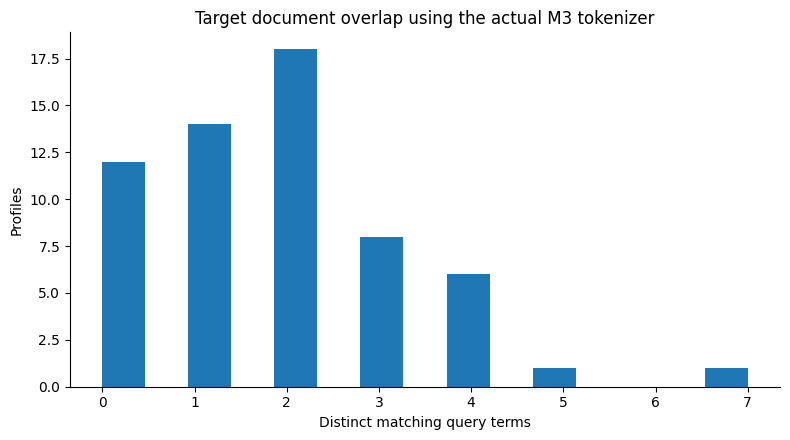

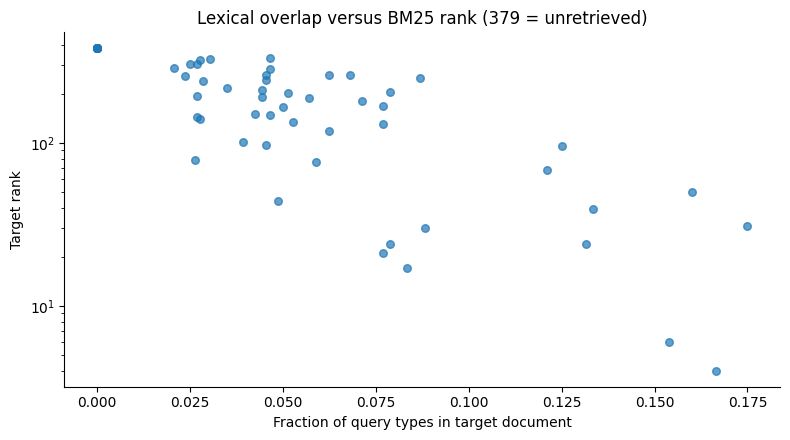

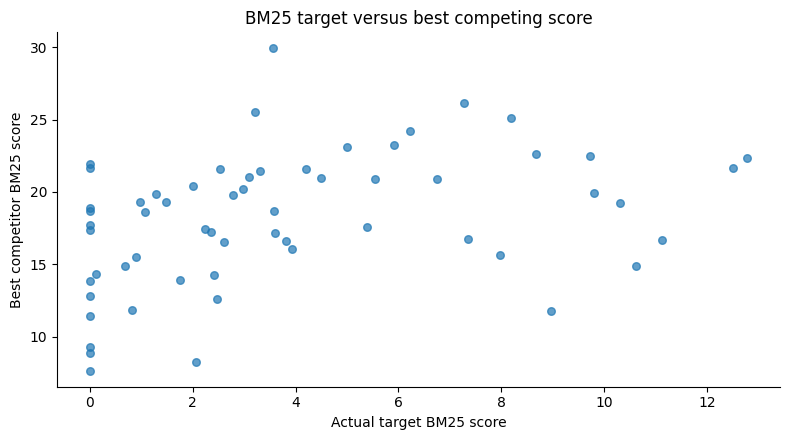

,profile_id,text,m3_matching_terms,m3_generic_matched_terms,m3_target_rank,m3_competitor_code,m3_competitor_token_overlap
0,D001,I interned at a community centre running programmes for elderly residents and honestly I really ...,"community, records, research","community, records, research",206.0,21-2011.00,6
24,D025,"Helping people is really what drives me, and my internship at a family service centre, running w...","all, records, such, support","records, such, support",250.0,21-1014.00,12
25,D026,"Leading a team and convincing people to buy into an idea is where I feel most alive, like when I...",,,NaN,11-1031.00,6
44,D045,What gets me most excited is digging into a problem and running my own little experiments until ...,,,NaN,15-1212.00,4


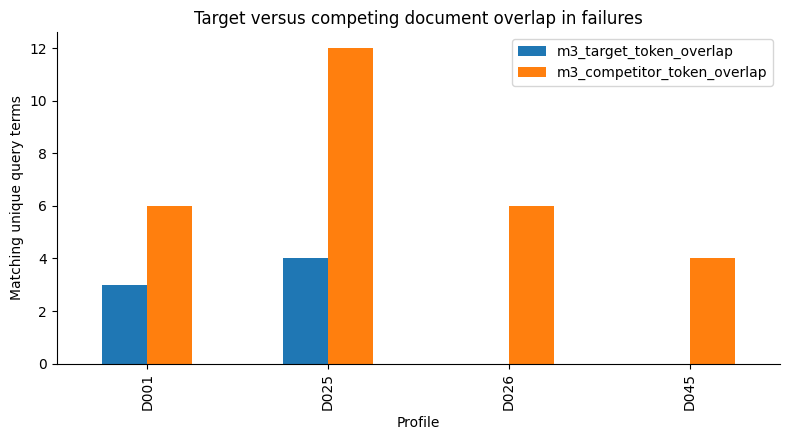

**Finding:** 12/60 targets have zero lexical overlap and 12 are absent from positive BM25 retrieval. Median query coverage is 4.5%.

**Interpretation:** Positive term overlap is not necessarily positive preference evidence. Inspect generic terms and the original text alongside each competing occupation.

**Limitation:** Token matches do not prove that background or negation caused a particular ranking. Stemming, document coverage and human-relevant vocabulary are not independently tested here.

**Next experiment:** Compare one query/document or tokenization change at a time; separately test stance/evidence filtering with fixed tracked interests.

In [8]:
display(diag[["m3_target_token_overlap","m3_query_coverage","m3_weighted_overlap","m3_oov_share","m3_target_score","m3_competitor_score"]].describe())
plt.figure(); plt.hist(diag.m3_target_token_overlap, bins=15)
chart("Target document overlap using the actual M3 tokenizer", "Distinct matching query terms", "Profiles")
scatter(diag.m3_query_coverage, rank_for_plot(diag.m3_target_rank), "Lexical overlap versus BM25 rank (379 = unretrieved)", "Fraction of query types in target document", "Target rank", True)
scatter(diag.m3_target_score, diag.m3_competitor_score, "BM25 target versus best competing score", "Actual target BM25 score", "Best competitor BM25 score")
lexical_examples = diag.sort_values('m3_margin').head(4)
display(lexical_examples[["profile_id","text","m3_matching_terms","m3_generic_matched_terms","m3_target_rank","m3_competitor_code","m3_competitor_token_overlap"]])
lexical_examples.set_index('profile_id')[["m3_target_token_overlap","m3_competitor_token_overlap"]].plot.bar()
chart("Target versus competing document overlap in failures", "Profile", "Matching unique query terms")
zero_overlap = int(diag.m3_target_token_overlap.eq(0).sum())
unretrieved = int(diag.m3_target_rank.isna().sum())
conclude("B2", f"{zero_overlap}/{len(diag)} targets have zero lexical overlap and {unretrieved} are absent from positive BM25 retrieval. Median query coverage is {diag.m3_query_coverage.median():.1%}.",
         "Positive term overlap is not necessarily positive preference evidence. Inspect generic terms and the original text alongside each competing occupation.",
         "Token matches do not prove that background or negation caused a particular ranking. Stemming, document coverage and human-relevant vocabulary are not independently tested here.", "Compare one query/document or tokenization change at a time; separately test stance/evidence filtering with fixed tracked interests.")

## B3 - Semantic tasks and aggregation

**Research question:** Is semantic representation or occupation aggregation limiting retrieval?

**Hypothesis:** A strong isolated task match can coexist with a low mean-of-sentence-maxima score, and generic tasks may match several sentences.

**Data and methodology:** Use saved task evidence/scores and the actual pinned encoder/index for per-sentence winning-task diagnostics. Do not rebuild embeddings or change mean-of-maxima aggregation. Domain cue counts are only a text-detail proxy, not human specificity judgments.

Actual pinned model/cache reused; task embeddings were not rebuilt.

,m4_target_task_similarity,m4_target_score,m4_margin,dominant_task_share,distinct_winning_tasks,best_task_minus_aggregate
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,0.346362,0.254015,-0.121698,0.443889,3.316667,0.092348
std,0.079654,0.053818,0.058127,0.193588,1.142279,0.054377
min,0.105502,0.105430,-0.305986,0.166667,1.000000,0.000000
25%,0.291144,0.214781,-0.155812,0.250000,3.000000,0.061368
50%,0.352596,0.256826,-0.120305,0.500000,3.000000,0.093558
75%,0.399411,0.290600,-0.089574,0.500000,4.000000,0.117837
max,0.528683,0.370566,-0.001887,1.000000,6.000000,0.248943


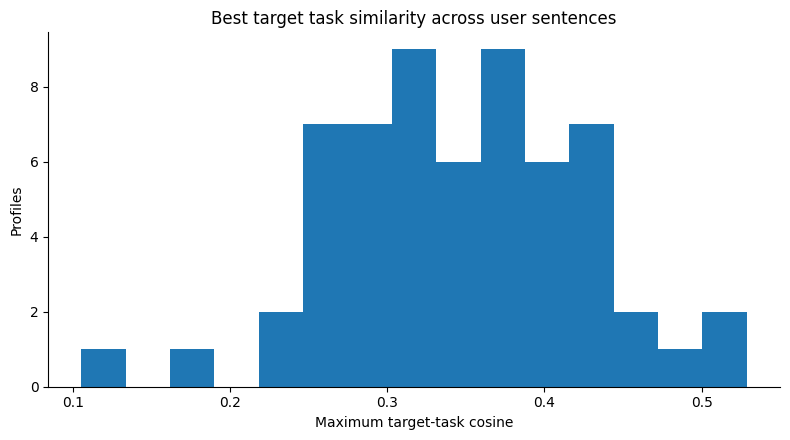

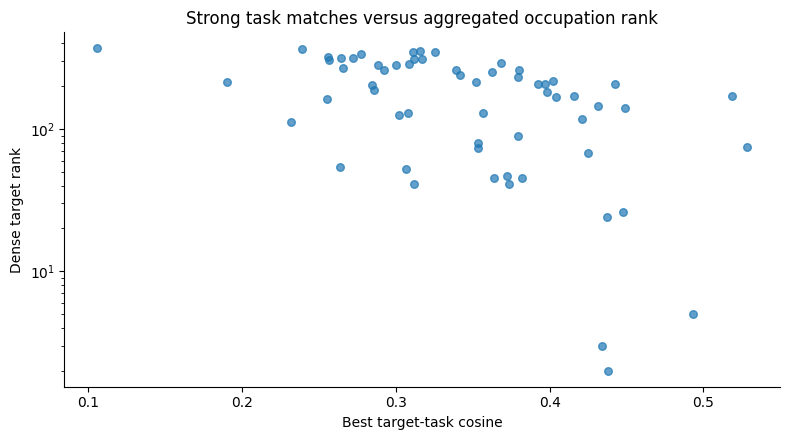

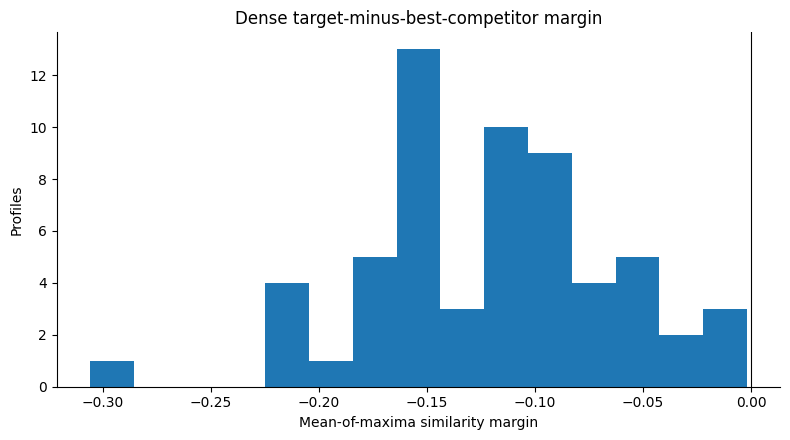

,profile_id,text,m4_target_best_task,m4_competitor_code,m4_competitor_best_task,m4_target_task_similarity,m4_target_score,m4_competitor_score
11,D012,"designing stuff and drawing is what i'm most into, i'll spend hours on a poster just because it'...","Travel over photographed areas to observe, identify, record, and verify all relevant features.",27-1011.00,Create custom illustrations or other graphic elements.,0.190110,0.190110,0.496096
39,D040,"Helping people through tough times means the most to me, and supporting friends during exam seas...","Obtain, compile, and record patient medical data, including health history, progress notes, and ...",25-2051.00,Encourage students to explore learning opportunities or persevere with challenging tasks to prep...,0.239216,0.141192,0.365187
29,D030,"not super sure yet but i kinda like analysing stuff, like digging into why my grades dipped one ...",Supervise activities of other forestry workers.,25-3031.00,Grade students' assignments and exams.,0.105502,0.105430,0.321993
9,D010,"I think what I'm most into is taking the lead and convincing people, like when I pitched our gro...","Approve proposals for the acquisition, replacement, or repair of biofuels processing equipment o...",27-2012.00,Study and research scripts to determine how they should be directed.,0.315635,0.201695,0.414991


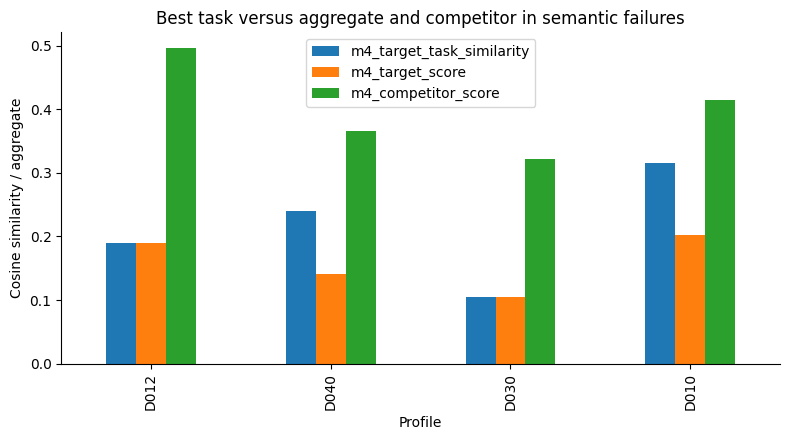

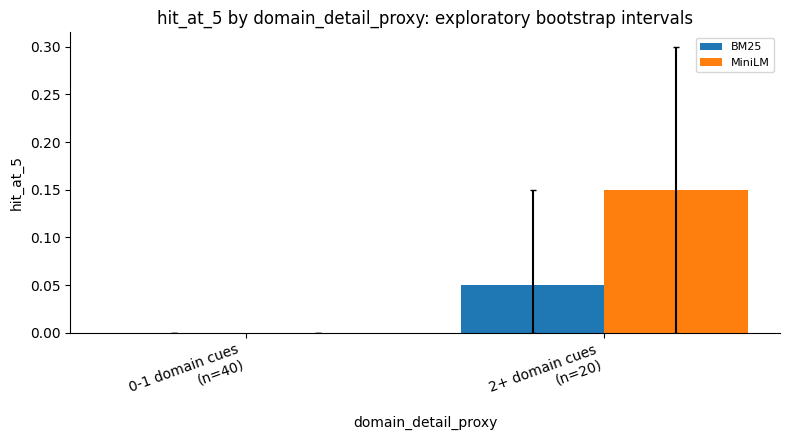

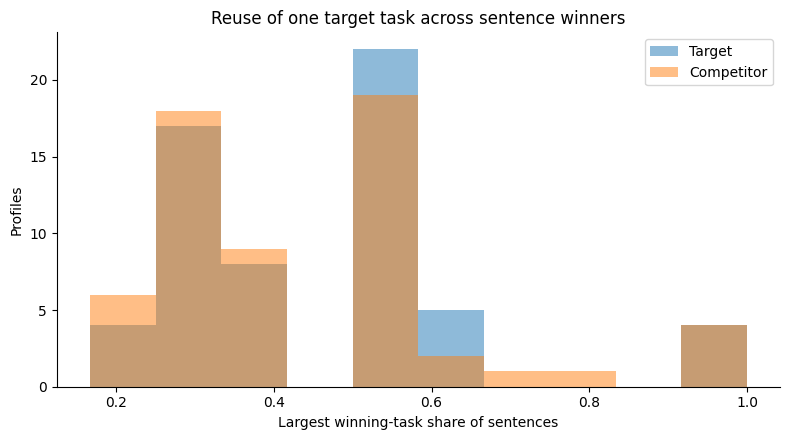

,profile_id,role,sentence,task_id,task,similarity
66,D010,target,"I think what I'm most into is taking the lead and convincing people, like when I pitched our gro...",15449,Provide training to subordinate or new employees to improve biofuels plant safety or increase th...,0.157653
67,D010,target,"My dad's an electrician, by the way.",15454,"Supervise production employees in the manufacturing of biofuels, such as biodiesel or ethanol.",0.312402
68,D010,target,Being in charge of a project and setting the direction is the part I look forward to.,15460,"Approve proposals for the acquisition, replacement, or repair of biofuels processing equipment o...",0.315635
69,D010,target,Negotiating who does what is kinda fun too.,15454,"Supervise production employees in the manufacturing of biofuels, such as biodiesel or ethanol.",0.160664
70,D010,target,"I'm not into creative stuff like drawing, writing stories or designing things at all.",15452,Draw samples of biofuels products or secondary by-products for quality control testing.,0.062120
71,D010,best competitor,"I think what I'm most into is taking the lead and convincing people, like when I pitched our gro...",22521,"Confer with technical directors, managers, crew members, and writers to discuss details of produ...",0.306017
72,D010,best competitor,"My dad's an electrician, by the way.",22520,"Supervise and coordinate the work of camera, lighting, design, and sound crew members.",0.414359
73,D010,best competitor,Being in charge of a project and setting the direction is the part I look forward to.,22519,Study and research scripts to determine how they should be directed.,0.492801
74,D010,best competitor,Negotiating who does what is kinda fun too.,22534,"Negotiate with parties, including independent producers and the distributors and broadcasters wh...",0.423141
75,D010,best competitor,"I'm not into creative stuff like drawing, writing stories or designing things at all.",22533,Compose and edit scripts or provide screenwriters with story outlines from which scripts can be ...,0.438639


**Finding:** Median best target-task similarity is 0.353, versus median aggregated score 0.257. Live sentence diagnostics cover 60/60 profiles.

**Interpretation:** Best single-task similarity and occupation mean-of-maxima answer different questions; task reuse/spread helps identify candidate aggregation bottlenecks.

**Limitation:** A high exact-target rank cannot diagnose an inadequate embedding model. Task coverage, broad evidence and competing plausible tasks may explain part of the result; all evidence remains provisional.

**Next experiment:** Freeze model/text and compare one alternative task aggregation in a separate registered experiment after human review.

In [9]:
display(Markdown(semantic_status))
display(diag[["m4_target_task_similarity","m4_target_score","m4_margin","dominant_task_share","distinct_winning_tasks","best_task_minus_aggregate"]].describe())
plt.figure(); plt.hist(diag.m4_target_task_similarity.dropna(), bins=15)
chart("Best target task similarity across user sentences", "Maximum target-task cosine", "Profiles")
scatter(diag.m4_target_task_similarity, diag.m4_target_rank, "Strong task matches versus aggregated occupation rank", "Best target-task cosine", "Dense target rank", True)
plt.figure(); plt.hist(diag.m4_margin.dropna(), bins=15); plt.axvline(0,color='black',lw=.8)
chart("Dense target-minus-best-competitor margin", "Mean-of-maxima similarity margin", "Profiles")
sem_examples = diag.sort_values('m4_margin').head(4)
display(sem_examples[["profile_id","text","m4_target_best_task","m4_competitor_code","m4_competitor_best_task","m4_target_task_similarity","m4_target_score","m4_competitor_score"]])
sem_examples.set_index('profile_id')[["m4_target_task_similarity","m4_target_score","m4_competitor_score"]].plot.bar()
chart("Best task versus aggregate and competitor in semantic failures", "Profile", "Cosine similarity / aggregate")
group_chart("domain_detail_proxy", methods=("m3","m4"))
if not semantic_live.empty:
    plt.figure(); plt.hist(diag.dominant_task_share.dropna(),bins=10,alpha=.5,label="Target"); plt.hist(diag.competitor_dominant_task_share.dropna(),bins=10,alpha=.5,label="Competitor"); plt.legend()
    chart("Reuse of one target task across sentence winners", "Largest winning-task share of sentences", "Profiles")
    display(sentence_matches[sentence_matches.profile_id.isin(sem_examples.profile_id)].head(20))
conclude("B3", f"Median best target-task similarity is {diag.m4_target_task_similarity.median():.3f}, versus median aggregated score {diag.m4_target_score.median():.3f}. Live sentence diagnostics cover {len(semantic_live)}/{len(diag)} profiles.",
         "Best single-task similarity and occupation mean-of-maxima answer different questions; task reuse/spread helps identify candidate aggregation bottlenecks.",
         "A high exact-target rank cannot diagnose an inadequate embedding model. Task coverage, broad evidence and competing plausible tasks may explain part of the result; all evidence remains provisional.", "Freeze model/text and compare one alternative task aggregation in a separate registered experiment after human review.")

## C1 - Exact-target versus graded relevance

**Research question:** Are exact misses still retrieving labeled related occupations?

**Hypothesis:** Exact-target failures may sometimes retain graded relevance, but related labels may also be sparse or incomplete.

**Data and methodology:** Reuse evaluator target=4, Primary-Short=3, Primary-Long=2, Supplemental=1, pool filtering and maximum-grade deduplication. Count grade>0 occupations in top five/ten; never equate these labels with human suitability.

,hit_at_1,hit_at_5,hit_at_10,mrr,ndcg_at_5,ndcg_at_10,relevant_top5,relevant_top10
method,,,,,,,,
M1,0.033333,0.166667,0.433333,0.135636,0.151459,0.203471,1.566667,2.950000
BM25,0.000000,0.016667,0.033333,0.016099,0.014219,0.020544,0.183333,0.350000
MiniLM,0.000000,0.050000,0.050000,0.025520,0.028859,0.031444,0.266667,0.533333
M1+BM25,0.016667,0.133333,0.200000,0.084887,0.098101,0.116610,0.916667,1.733333
M1+MiniLM,0.016667,0.116667,0.200000,0.086552,0.103499,0.121640,1.050000,1.850000
BM25+MiniLM,0.000000,0.033333,0.050000,0.023789,0.018654,0.023739,0.183333,0.416667
Three-way RRF,0.000000,0.050000,0.116667,0.045221,0.051315,0.068509,0.616667,1.216667


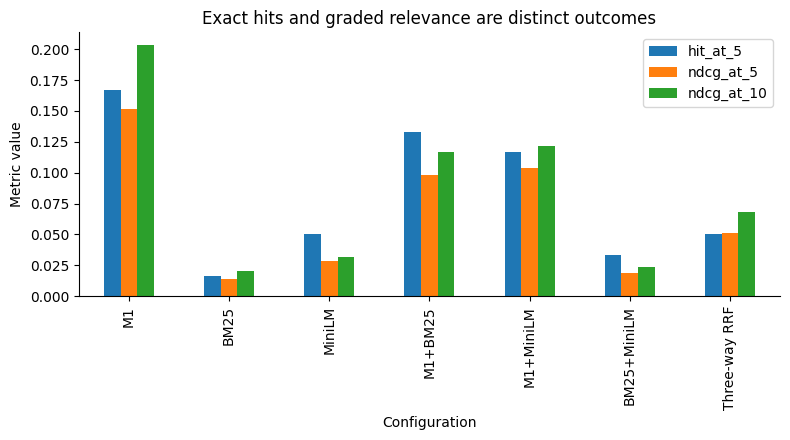

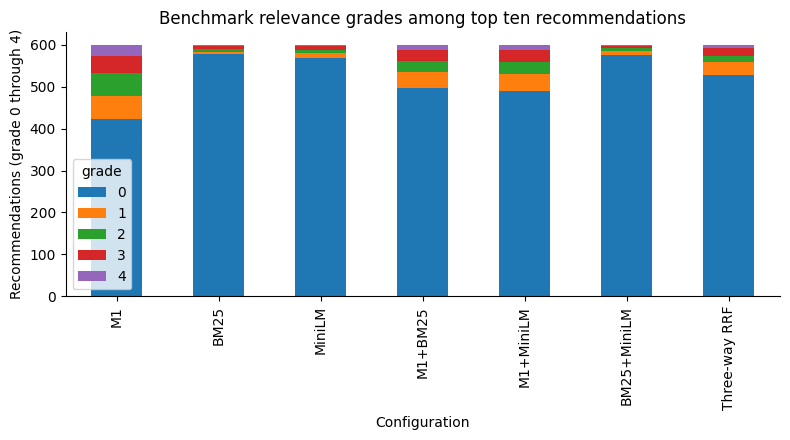

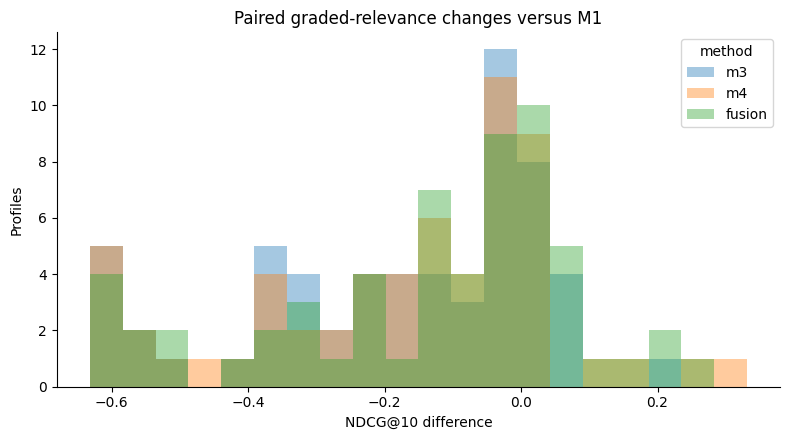

,profile_id,method,target_rank,relevant_top5,ndcg_at_10
18,D019,m1,8.0,3,0.624977
44,D045,m1,8.0,4,0.543981
257,D018,m1_m4,37.0,5,0.500018
37,D038,m1,7.0,2,0.464433
12,D013,m1,8.0,3,0.432323
217,D038,m1_m3,7.0,3,0.427122
256,D017,m1_m4,9.0,2,0.390789
197,D018,m1_m3,7.0,3,0.379683
31,D032,m1,10.0,3,0.376707
264,D025,m1_m4,12.0,3,0.365044


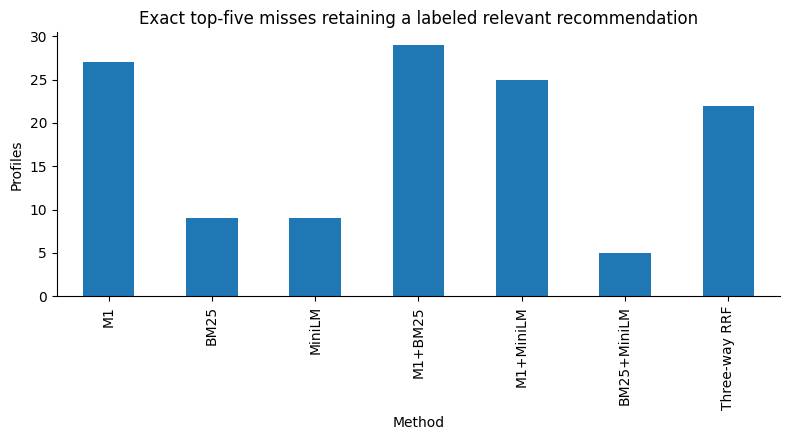

**Finding:** There are 126 method-profile cases with a missed exact top-five target but at least one labeled relevant top-five occupation.

**Interpretation:** Some exact misses preserve benchmark-related relevance, so Hit@5 alone is incomplete. The graded metrics still quantify how much relatedness survives.

**Limitation:** Related occupations are O*NET/benchmark labels, not independently verified relevance for this synthetic person. Unlabeled plausible jobs receive grade zero.

**Next experiment:** Blindly review a sample of top recommendations before interpreting grade-zero results as universally unsuitable.

In [10]:
display(metrics.groupby('method',sort=False)[list(METRICS)+['relevant_top5','relevant_top10']].mean().rename(index=NAMES))
overview[['hit_at_5','ndcg_at_5','ndcg_at_10']].rename(index=NAMES).plot.bar()
chart("Exact hits and graded relevance are distinct outcomes", "Configuration", "Metric value")
grade_counts = grade_rows.groupby(['method','grade']).size().unstack(fill_value=0).reindex(RUNS).reindex(columns=range(5),fill_value=0)
grade_counts.rename(index=NAMES).plot.bar(stacked=True)
chart("Benchmark relevance grades among top ten recommendations", "Configuration", "Recommendations (grade 0 through 4)")
delta = metric_wide['ndcg_at_10'].sub(metric_wide['ndcg_at_10']['m1'],axis=0)
delta[['m3','m4','fusion']].plot.hist(alpha=.4,bins=20)
chart("Paired graded-relevance changes versus M1", "NDCG@10 difference", "Profiles")
related_misses = metrics[(metrics.hit_at_5==0)&(metrics.relevant_top5>0)]
display(related_misses[['profile_id','method','target_rank','relevant_top5','ndcg_at_10']].sort_values('ndcg_at_10',ascending=False).head(12))
related_misses.groupby('method').size().reindex(RUNS,fill_value=0).rename(index=NAMES).plot.bar()
chart("Exact top-five misses retaining a labeled relevant recommendation", "Method", "Profiles")
conclude("C1", f"There are {len(related_misses)} method-profile cases with a missed exact top-five target but at least one labeled relevant top-five occupation.",
         "Some exact misses preserve benchmark-related relevance, so Hit@5 alone is incomplete. The graded metrics still quantify how much relatedness survives.",
         "Related occupations are O*NET/benchmark labels, not independently verified relevance for this synthetic person. Unlabeled plausible jobs receive grade zero.", "Blindly review a sample of top recommendations before interpreting grade-zero results as universally unsuitable.")

## C2 - Complementarity under RIASEC ambiguity

**Research question:** Does retrieval help when numerical scoring struggles?

**Hypothesis:** Standalone retrieval improvements may concentrate in difficult numerical cases, yet fusion can erase them.

**Data and methodology:** Explore M1 rank>10, provided twins and crowded score bands as separate descriptors. Positive rank improvement means M1 rank minus retrieval rank; unretrieved BM25 ranks remain missing and are counted explicitly.

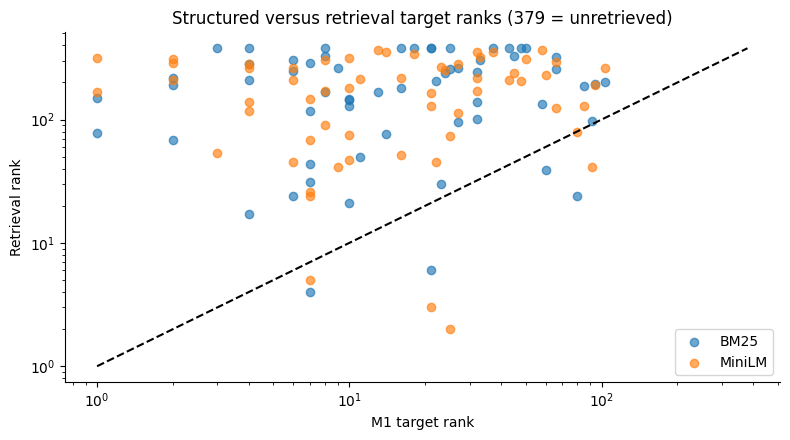

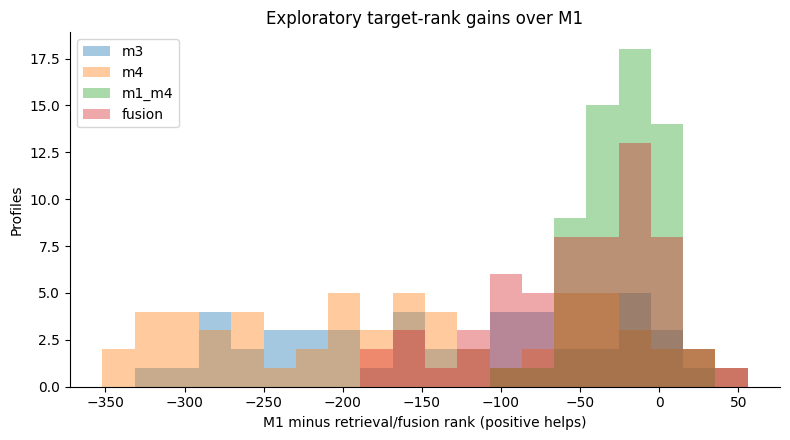

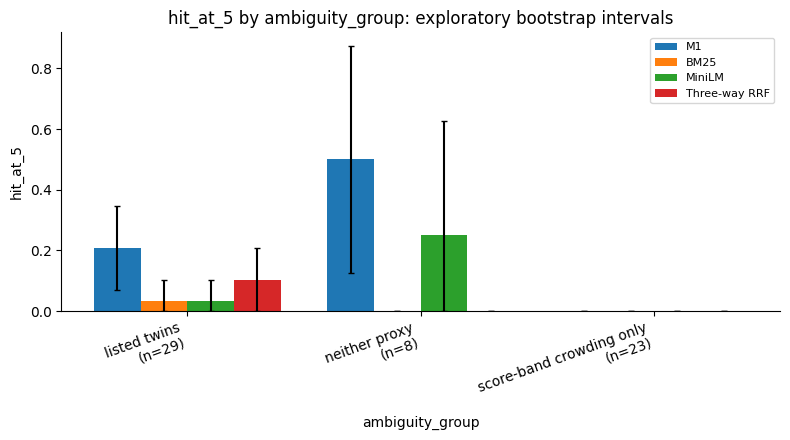

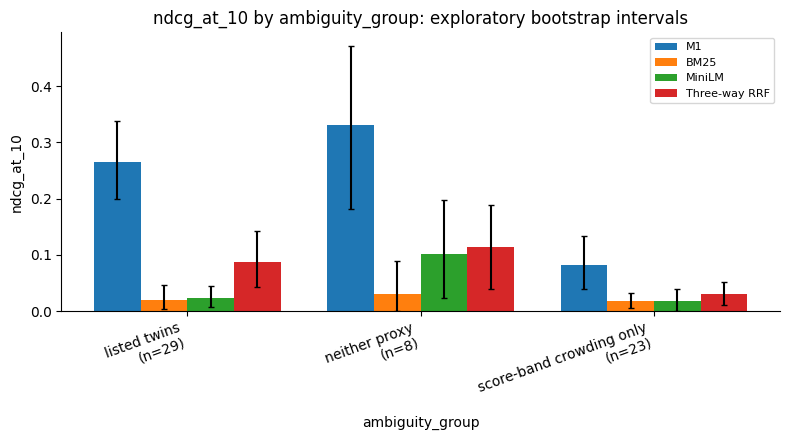

,profile_id,target_title,text,has_twins,score_band_count,m1_target_rank,m3_target_rank,m4_target_rank,m1_m4_target_rank,fusion_target_rank
40,D041,Computer Programmers,Keeping things organised gives me the most satisfaction; during my internship I reconciled invoi...,False,4,25,256.0,2,2,8
3,D004,"Architects, Except Landscape and Naval","Making things is what I'm happiest doing; I sketch, design posters and edit little videos for fu...",False,2,21,6.0,3,10,8
36,D037,Farm and Home Management Educators,Helping others is what makes me happiest: my mum runs a small childcare centre and I help out th...,False,10,92,97.0,41,59,63
0,D001,"Forestry and Conservation Science Teachers, Postsecondary",I interned at a community centre running programmes for elderly residents and honestly I really ...,True,3,22,206.0,45,28,46
2,D003,Project Management Specialists,"what i like most is taking charge and persuading people, like running my hall's fundraiser. hand...",True,3,16,180.0,52,13,26
5,D006,Robotics Engineers,"i guess figuring out why stuff works is what i'm most into, like taking apart a problem in my la...",True,9,25,NaN,74,31,65
50,D051,Curators,"I love creating things, especially designing graphics and editing videos for my hall events. I a...",False,19,80,24.0,80,81,27
38,D039,Biologists,"idk if this counts but i can spend hours reading about why things happen, like why some songs go...",False,17,27,95.0,113,57,61
19,D020,Manufacturing Engineers,I'm honestly not sure what I enjoy yet. I find learning how things work kind of interesting. My ...,False,34,66,259.0,125,80,143
8,D009,"Law Teachers, Postsecondary","my mum runs a childcare centre and i help out during holidays, honestly i really like it, lookin...",True,7,21,NaN,129,40,107


**Finding:** Among 34 profiles with M1 rank>10, dense-only retrieves 2 exact targets in the top five. BM25 has 12 missing target ranks overall.

**Interpretation:** Complementary cases exist or fail on their own evidence; subgroup figures distinguish different ambiguity descriptors rather than treating all misses alike.

**Limitation:** Groups and thresholds are exploratory and small. Text sufficiency is not established by either numerical ambiguity or a retrieval miss.

**Next experiment:** Create reviewed occupation-specific contrasts within ambiguous RIASEC families before claiming robust disambiguation.

In [11]:
plt.figure()
for method in ('m3','m4'):
    plt.scatter(diag.m1_target_rank,rank_for_plot(diag[f'{method}_target_rank']),label=NAMES[method],alpha=.65)
plt.plot([1,len(occupation)+1],[1,len(occupation)+1],color='black',ls='--'); plt.xscale('log'); plt.yscale('log'); plt.legend()
chart("Structured versus retrieval target ranks (379 = unretrieved)", "M1 target rank", "Retrieval rank")
rank_changes = pd.DataFrame({m: diag.m1_target_rank-diag[f'{m}_target_rank'] for m in ('m3','m4','m1_m4','fusion')})
rank_changes.plot.hist(alpha=.4,bins=20)
chart("Exploratory target-rank gains over M1", "M1 minus retrieval/fusion rank (positive helps)", "Profiles")
group_chart("ambiguity_group"); group_chart("ambiguity_group", "ndcg_at_10")
difficult = diag[diag.m1_target_rank>10]
display(difficult[['profile_id','target_title','text','has_twins','score_band_count','m1_target_rank','m3_target_rank','m4_target_rank','m1_m4_target_rank','fusion_target_rank']].sort_values('m4_target_rank').head(10))
gains = int((difficult.m4_target_rank<=5).sum())
conclude("C2", f"Among {len(difficult)} profiles with M1 rank>10, dense-only retrieves {gains} exact targets in the top five. BM25 has {int(diag.m3_target_rank.isna().sum())} missing target ranks overall.",
         "Complementary cases exist or fail on their own evidence; subgroup figures distinguish different ambiguity descriptors rather than treating all misses alike.",
         "Groups and thresholds are exploratory and small. Text sufficiency is not established by either numerical ambiguity or a retrieval miss.", "Create reviewed occupation-specific contrasts within ambiguous RIASEC families before claiming robust disambiguation.")

## C3 - Text specificity and target identifiability

**Research question:** Could a judge infer the role from text before seeing the target?

**Hypothesis:** Many texts may express broad interests or distracting exposure rather than identify a unique role.

**Data and methodology:** Select 18 profiles by deterministic greedy coverage of style/tier/dominant type, plants and strong/weak retrieval. Stage 1 passes only text into a transparent fixed heuristic; save proposals before revealing targets. All proposals are provisional; human blind review is a separate preserved file.

**Annotation protocol:** `specific` means explicit tasks/domain; `partially_specific` narrows a family; `broad` communicates general interests; `misleading` flags potentially distracting exposure/uncertainty or contradictions. The automated heuristic only detects a limited cue vocabulary and exposure/uncertainty co-occurrence; it cannot reliably resolve contradictions. No category proves exact-role identifiability.

For human validation, give the reviewer **only** `specificity_blind_inputs.csv`. Record a category and text-only rationale in `specificity_human_reviews.csv` with `status=verified` and a reviewer ID **before** revealing targets. Stage 2 uses the target-revealed table to assess compatibility independently. Do not infer blindness for an already target-exposed reviewer. No human review is fabricated by this notebook.


In [12]:
sample_ids = select_sample(diag,18)
blind = diag.set_index('profile_id').loc[sample_ids,['text']].reset_index()
assert list(blind.columns)==['profile_id','text']
blind.to_csv(OUT/'specificity_blind_inputs.csv',index=False)
proposals = blind.copy()
proposals[['proposed_category','blind_rationale']] = pd.DataFrame([text_only_proposal(text) for text in blind.text],index=blind.index)
proposals['human_review_status']='unreviewed'
proposals.to_csv(OUT/'specificity_blind_proposals.csv',index=False)
blind_hash = sha(OUT/'specificity_blind_proposals.csv')
display(proposals[['profile_id','text','proposed_category','blind_rationale','human_review_status']])
review_path=OUT/'specificity_human_reviews.csv'
if not review_path.exists():
    pd.DataFrame(columns=['profile_id','category','reviewer','status','blind_rationale']).to_csv(review_path,index=False)
# This cell completes the blind automated stage. The next cell reveals labels.

,profile_id,text,proposed_category,blind_rationale,human_review_status
0,D013,I enjoy analysing things and figuring out how they work. I also like tinkering with gadgets and ...,broad,No predefined domain/task cues; primarily general preferences under this limited heuristic rubric.,unreviewed
1,D042,"Tbh what gets me going is solving puzzles and digging into why something happens, like debugging...",specific,"At least two explicit domain/task cue tokens in one family: {'software': ['code', 'debugging']};...",unreviewed
2,D058,"My mum is a volunteer counsellor and I grew up tagging along to help at community events, so may...",misleading,"Exposure and uncertainty markers co-occur; possible distracting background, not a verified false...",unreviewed
3,D023,"Nothing satisfies me more than turning a messy spreadsheet into perfect order, with every record...",broad,No predefined domain/task cues; primarily general preferences under this limited heuristic rubric.,unreviewed
4,D047,I get a real kick out of leading a group project and convincing people to get behind an idea. I ...,misleading,"Exposure and uncertainty markers co-occur; possible distracting background, not a verified false...",unreviewed
5,D046,"I love creating things, whether it's sketching, designing posters for my CCA or writing short st...",specific,"At least two explicit domain/task cue tokens in one family: {'creative': ['designing', 'posters'...",unreviewed
6,D015,"I love working with my hands, building and repairing things is super satisfying. I also enjoy fi...",broad,No predefined domain/task cues; primarily general preferences under this limited heuristic rubric.,unreviewed
7,D032,"What I like most is working out why something isn't behaving the way it should, like tracing why...",partially_specific,Some domain/task cues narrow a family: {'software': ['code']}; insufficient evidence of a unique...,unreviewed
8,D056,I really enjoy working through tough problems and analysing data until things make sense. I also...,broad,No predefined domain/task cues; primarily general preferences under this limited heuristic rubric.,unreviewed
9,D007,Taking charge and persuading people is what I'm happiest doing; I led my CCA's recruitment drive...,partially_specific,Some domain/task cues narrow a family: {'engineering': ['machines']}; insufficient evidence of a...,unreviewed


,profile_id,text,target_code,target_title,proposed_category,blind_rationale,human_review_status,target_compatibility_review
0,D013,I enjoy analysing things and figuring out how they work. I also like tinkering with gadgets and ...,17-3026.01,Nanotechnology Engineering Technologists and Technicians,broad,No predefined domain/task cues; primarily general preferences under this limited heuristic rubric.,unreviewed,pending; assess after blind judgment is committed
1,D042,"Tbh what gets me going is solving puzzles and digging into why something happens, like debugging...",15-1253.00,Software Quality Assurance Analysts and Testers,specific,"At least two explicit domain/task cue tokens in one family: {'software': ['code', 'debugging']};...",unreviewed,pending; assess after blind judgment is committed
2,D058,"My mum is a volunteer counsellor and I grew up tagging along to help at community events, so may...",29-1071.01,Anesthesiologist Assistants,misleading,"Exposure and uncertainty markers co-occur; possible distracting background, not a verified false...",unreviewed,pending; assess after blind judgment is committed
3,D023,"Nothing satisfies me more than turning a messy spreadsheet into perfect order, with every record...",13-2051.00,Financial and Investment Analysts,broad,No predefined domain/task cues; primarily general preferences under this limited heuristic rubric.,unreviewed,pending; assess after blind judgment is committed
4,D047,I get a real kick out of leading a group project and convincing people to get behind an idea. I ...,11-3061.00,Purchasing Managers,misleading,"Exposure and uncertainty markers co-occur; possible distracting background, not a verified false...",unreviewed,pending; assess after blind judgment is committed
5,D046,"I love creating things, whether it's sketching, designing posters for my CCA or writing short st...",25-1031.00,"Architecture Teachers, Postsecondary",specific,"At least two explicit domain/task cue tokens in one family: {'creative': ['designing', 'posters'...",unreviewed,pending; assess after blind judgment is committed
6,D015,"I love working with my hands, building and repairing things is super satisfying. I also enjoy fi...",17-2051.00,Civil Engineers,broad,No predefined domain/task cues; primarily general preferences under this limited heuristic rubric.,unreviewed,pending; assess after blind judgment is committed
7,D032,"What I like most is working out why something isn't behaving the way it should, like tracing why...",19-1031.02,Range Managers,partially_specific,Some domain/task cues narrow a family: {'software': ['code']}; insufficient evidence of a unique...,unreviewed,pending; assess after blind judgment is committed
8,D056,I really enjoy working through tough problems and analysing data until things make sense. I also...,15-1299.04,Penetration Testers,broad,No predefined domain/task cues; primarily general preferences under this limited heuristic rubric.,unreviewed,pending; assess after blind judgment is committed
9,D007,Taking charge and persuading people is what I'm happiest doing; I led my CCA's recruitment drive...,13-1075.00,Labor Relations Specialists,partially_specific,Some domain/task cues narrow a family: {'engineering': ['machines']}; insufficient evidence of a...,unreviewed,pending; assess after blind judgment is committed


,text_style,tier,dominant_positive,has_contradiction,has_familiarity
1,,9.0,,,
2,,9.0,,,
A,,,2.0,,
C,,,2.0,,
E,,,5.0,,
False,,,,14.0,13.0
I,,,6.0,,
R,,,1.0,,
S,,,2.0,,
True,,,,4.0,5.0


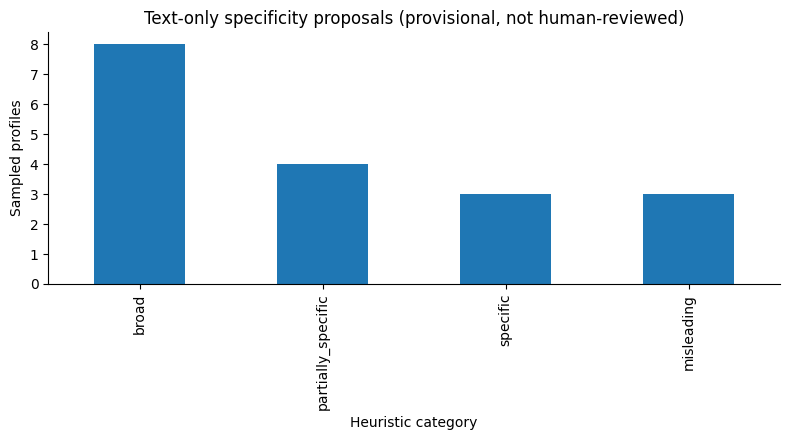

**Verified human categories: 0.** No performance-by-verified-specificity chart is generated. Provisional proposals must not be substituted for verified judgments.

**Finding:** Blind-stage proposals cover 18 stratified profiles: {'broad': 8, 'partially_specific': 4, 'specific': 3, 'misleading': 3}; verified human reviews: 0.

**Interpretation:** The table enables a reproducible text-first audit and later target compatibility review without passing labels into the automated judge.

**Limitation:** The cue heuristic is incomplete and may misclassify broad/task-specific language. No human claim about target inferability can be made until blind review is completed.

**Next experiment:** Complete the blind human audit, then reveal targets to test benchmark compatibility and occupation-family ambiguity.

In [13]:
assert sha(OUT/'specificity_blind_proposals.csv')==blind_hash
annotations = proposals.merge(diag[['profile_id','target_code','target_title','text_style','tier','dominant_positive','has_contradiction','has_familiarity','m3_target_rank','m4_target_rank']],on='profile_id',validate='one_to_one')
annotations['target_compatibility_review']='pending; assess after blind judgment is committed'
reviews=pd.read_csv(review_path,dtype=str).fillna('')
allowed={'specific','partially_specific','broad','misleading'}
if not reviews.empty:
    assert not reviews.profile_id.duplicated().any(), 'Human reviews must be unique per profile.'
    assert set(reviews.profile_id)<=set(sample_ids), 'Human review refers to a different blind sample.'
    assert set(reviews.category)<=allowed and reviews.reviewer.ne('').all(), 'Incomplete human category/reviewer.'
verified=reviews[reviews.status.eq('verified')]
annotations['human_review_status']=annotations.profile_id.map(verified.set_index('profile_id').status).fillna('unreviewed')
annotations.to_csv(OUT/'specificity_annotations.csv',index=False)
display(annotations[['profile_id','text','target_code','target_title','proposed_category','blind_rationale','human_review_status','target_compatibility_review']])
display(diag.set_index('profile_id').loc[sample_ids,['text_style','tier','dominant_positive','has_contradiction','has_familiarity']].astype(str).apply(lambda c:c.value_counts()).fillna(''))
annotations.proposed_category.value_counts().plot.bar()
chart("Text-only specificity proposals (provisional, not human-reviewed)", "Heuristic category", "Sampled profiles")
if len(verified):
    verified.category.value_counts().plot.bar(); chart("Verified blind human categories", "Human category", "Reviewed profiles")
    reviewed_long=long.merge(verified[['profile_id','category']],on='profile_id')
    display(reviewed_long.groupby(['category','method'])[['hit_at_5','ndcg_at_10']].agg(['mean','count']))
else:
    display(Markdown('**Verified human categories: 0.** No performance-by-verified-specificity chart is generated. Provisional proposals must not be substituted for verified judgments.'))
conclude("C3", f"Blind-stage proposals cover {len(annotations)} stratified profiles: {annotations.proposed_category.value_counts().to_dict()}; verified human reviews: {len(verified)}.",
         "The table enables a reproducible text-first audit and later target compatibility review without passing labels into the automated judge.",
         "The cue heuristic is incomplete and may misclassify broad/task-specific language. No human claim about target inferability can be made until blind review is completed.", "Complete the blind human audit, then reveal targets to test benchmark compatibility and occupation-family ambiguity.")

## D1 - Performance by input attributes

**Research question:** Which metadata groups are associated with retrieval difficulty?

**Hypothesis:** Failures may co-occur with style, length, interests, ambiguity or planted evidence.

**Data and methodology:** Report every subgroup n and deterministic profile-bootstrap intervals; no significance claims from tiny cells and no causal interpretation of metadata associations.

,attribute,group,method,n,metric,mean,ci_low,ci_high
0,text_style,full,fusion,48,hit_at_5,0.041667,0.000000,0.104167
3,text_style,full,m1,48,hit_at_5,0.187500,0.083333,0.291667
12,text_style,full,m3,48,hit_at_5,0.000000,0.000000,0.000000
18,text_style,full,m4,48,hit_at_5,0.041667,0.000000,0.104167
21,text_style,messy,fusion,12,hit_at_5,0.083333,0.000000,0.250000
...,...,...,...,...,...,...,...,...
375,has_familiarity,False,m4,47,hit_at_5,0.063830,0.000000,0.127660
378,has_familiarity,True,fusion,13,hit_at_5,0.076923,0.000000,0.230769
381,has_familiarity,True,m1,13,hit_at_5,0.230769,0.000000,0.461538
390,has_familiarity,True,m3,13,hit_at_5,0.000000,0.000000,0.000000


Style, length, and listed-twin charts already appear above. The remaining attributes are visualized here; all seven attributes are included in the exported metric table.

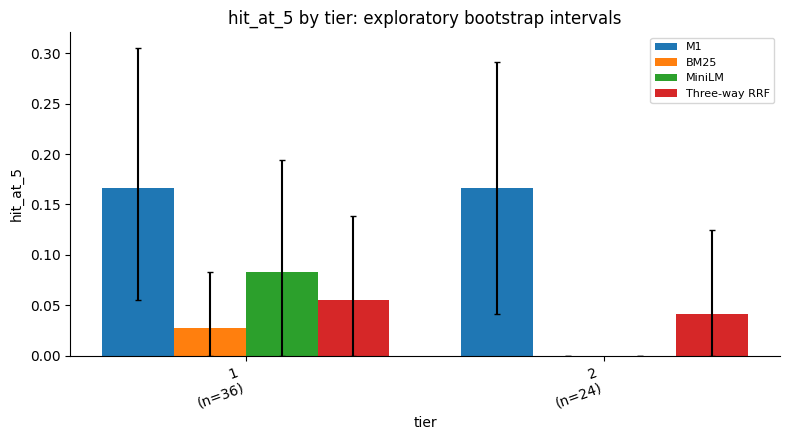

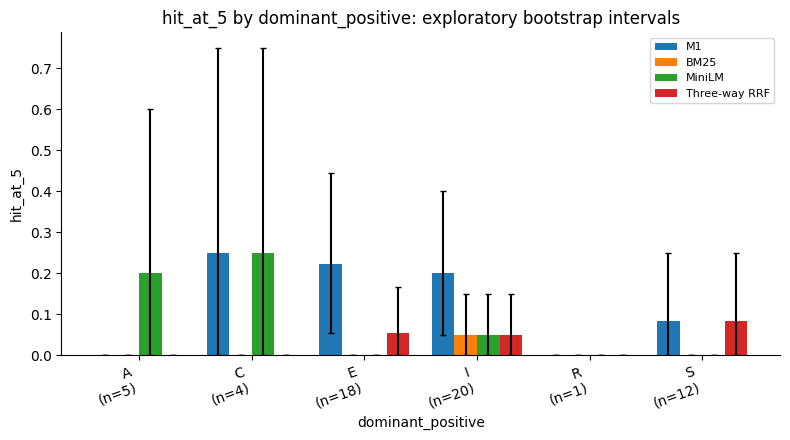

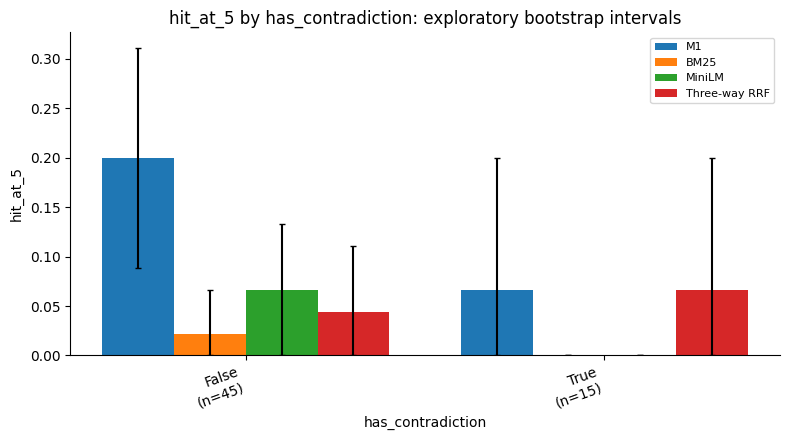

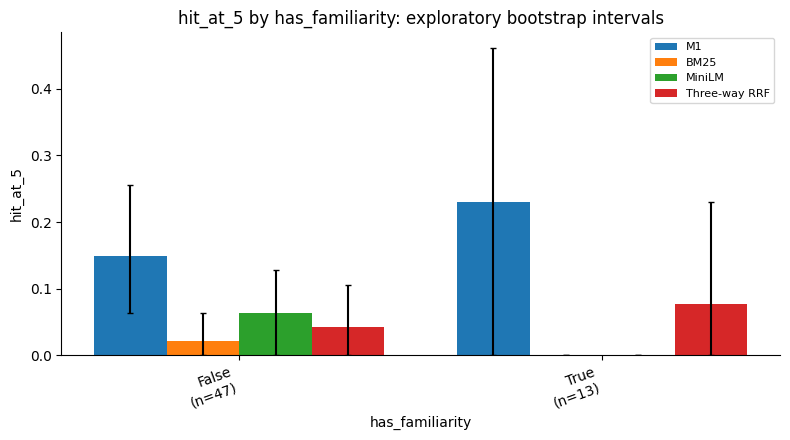

**Finding:** 3 displayed attribute groups contain fewer than 10 profiles; all group sizes and metric intervals are exported.

**Interpretation:** Metadata helps locate cases to inspect, but the same profile contributes to multiple overlapping groups.

**Limitation:** Many exploratory comparisons, correlated attributes, and only 60 profiles prevent strong subgroup or causal conclusions.

**Next experiment:** Predefine balanced strata for later development comparisons; retain paired profiles and fixed inputs.

In [14]:
attributes=['text_style','length_bin','tier','dominant_positive','has_twins','has_contradiction','has_familiarity']
subgroups=pd.concat([subgroup_metrics(long,column) for column in attributes],ignore_index=True)
display(subgroups[(subgroups.method.isin(['m1','m3','m4','fusion'])) & subgroups.metric.eq('hit_at_5')])
display(Markdown('Style, length, and listed-twin charts already appear above. The remaining attributes are visualized here; all seven attributes are included in the exported metric table.'))
for column in ('tier','dominant_positive','has_contradiction','has_familiarity'): group_chart(column)
small=int(subgroups[['attribute','group','n']].drop_duplicates().n.lt(10).sum())
conclude("D1", f"{small} displayed attribute groups contain fewer than 10 profiles; all group sizes and metric intervals are exported.",
         "Metadata helps locate cases to inspect, but the same profile contributes to multiple overlapping groups.",
         "Many exploratory comparisons, correlated attributes, and only 60 profiles prevent strong subgroup or causal conclusions.", "Predefine balanced strata for later development comparisons; retain paired profiles and fixed inputs.")

## D2 - Fusion regressions

**Research question:** Where does RRF preserve or erase component successes?

**Hypothesis:** Rank-only fusion can promote a competitor supported by weak channels and demote a strong M1 target.

**Data and methodology:** Reconstruct occupation rankings with the actual ReciprocalRankFusion class at k=60. Inspect per-profile ranks and target/winner reciprocal-rank contributions, with zero contribution for absent lexical targets.

,profile_id,target_code,m1_target_rank,m3_target_rank,m4_target_rank,fusion_target_rank,m1_success_fusion_failure,fusion_gain,all_components_fail,standalone_text_success_lost,rank_improvement,ndcg_at_10_change
20,D021,17-2141.01,50,NaN,309,230,False,False,True,False,-180,-0.025914
15,D016,11-3051.04,37,NaN,351,212,False,False,True,False,-175,0.000000
10,D011,29-1022.00,18,NaN,338,185,False,False,True,False,-167,-0.118009
59,D060,15-1231.00,66,324.0,293,229,False,False,True,False,-163,-0.023595
53,D054,13-2054.00,43,NaN,209,201,False,False,True,False,-158,0.062786
32,D033,11-3051.01,48,NaN,204,196,False,False,True,False,-148,-0.071869
27,D028,13-2071.00,33,305.0,322,154,False,False,True,False,-121,-0.031477
55,D056,15-1299.04,45,327.0,240,162,False,False,True,False,-117,-0.129111
44,D045,29-1242.00,8,NaN,307,120,False,False,True,False,-112,-0.543981
33,D034,19-1031.00,94,194.0,189,194,False,False,True,False,-100,0.000000


,profile_id,target_code,m1_target_rank,m3_target_rank,m4_target_rank,fusion_target_rank,m1_success_fusion_failure,fusion_gain,all_components_fail,standalone_text_success_lost,rank_improvement,ndcg_at_10_change
50,D051,25-4012.00,80,24.0,80,27,False,False,True,False,53,0.090083
36,D037,25-9021.00,92,97.0,41,63,False,False,True,False,29,0.000000
40,D041,15-1251.00,25,256.0,2,8,False,False,False,True,17,0.143625
3,D004,17-1011.00,21,6.0,3,8,False,False,False,True,13,0.204616
41,D042,15-1253.00,7,4.0,5,2,False,True,False,False,5,0.254394
16,D017,25-1062.00,7,31.0,26,4,False,True,True,False,3,0.204246
14,D015,17-2051.00,23,30.0,268,21,False,False,True,False,2,0.034812
30,D031,11-3121.00,4,17.0,118,3,False,False,False,False,1,-0.029034
42,D043,13-2052.00,10,21.0,182,10,False,False,True,False,0,-0.035699
4,D005,15-1299.03,6,24.0,208,10,False,False,True,False,-4,0.045063


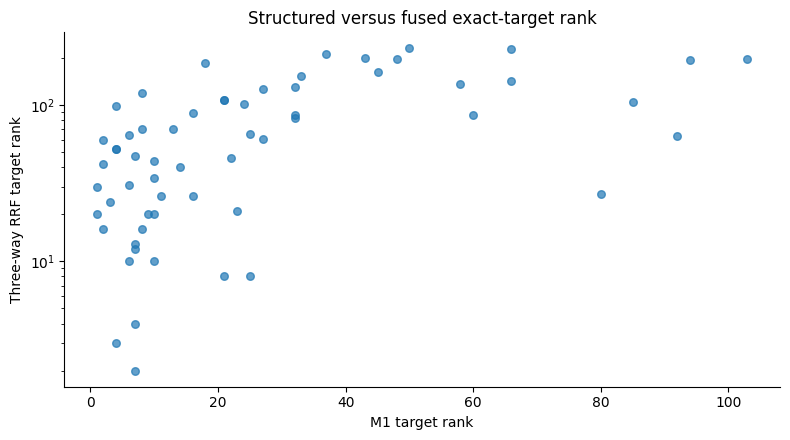

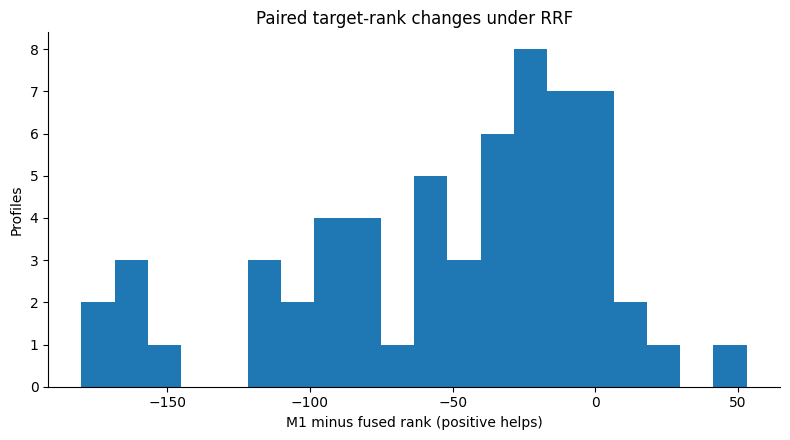

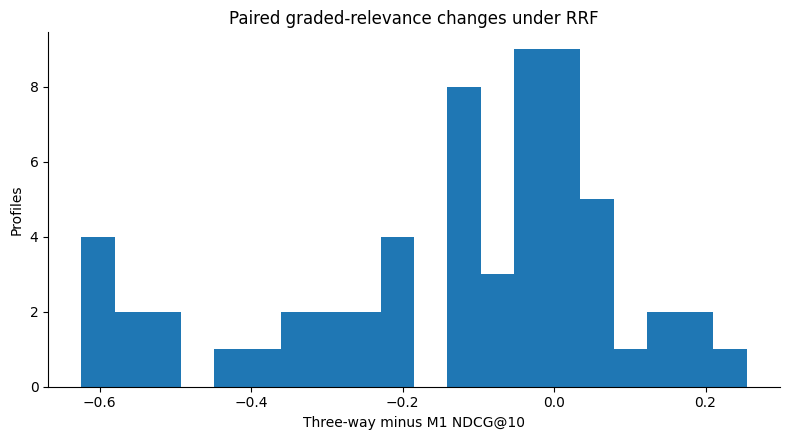

,profile_id,occupation,role,semantic,structured,lexical
0,D021,17-2141.01,target,0.002710,0.009091,0.000000
1,D021,17-2031.00,fused winner,0.015385,0.012821,0.015625
2,D016,11-3051.04,target,0.002433,0.010309,0.000000
3,D016,11-1021.00,fused winner,0.013333,0.014286,0.006289
4,D017,25-1062.00,target,0.011628,0.014925,0.010989
5,D017,25-1121.00,fused winner,0.015385,0.016393,0.011364


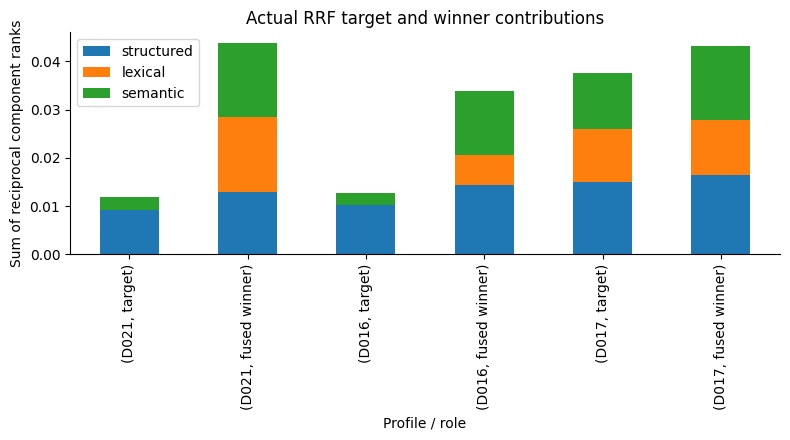

**Finding:** RRF loses 9 M1 top-five successes and gains 2; 2 standalone text successes are lost.

**Interpretation:** The contribution breakdown directly explains the fusion arithmetic. It does not explain why an upstream component preferred a competitor.

**Limitation:** Rank-only fusion discards score confidence; assigning a specific semantic/negation cause requires further controlled evidence.

**Next experiment:** If warranted, test one fixed fusion-weight change with exactly the same component rankings; keep equal-weight RRF as the control.

In [15]:
from recommender.fusion import ReciprocalRankFusion
from recommender.components import ComponentRanking, ComponentScore
for pid in diag.profile_id:
    components={}
    for method, signal in [('m1','structured'),('m3','lexical'),('m4','semantic')]:
        items=predictions[method][pid]
        components[method]=ComponentRanking('usable',tuple(ComponentScore(r['code'],r['signals'][signal]['score'],r['rank']) for r in items)) if items else ComponentRanking('unusable',reason='No positive retrieval')
    actual=ReciprocalRankFusion(60).fuse(components)
    saved=predictions['fusion'][pid]
    assert [(r.code,r.score,r.rank) for r in actual.occupations]==[(r['code'],r['rrf_score'],r['rank']) for r in saved]
fusion_cases=diag[['profile_id','target_code','m1_target_rank','m3_target_rank','m4_target_rank','fusion_target_rank']].copy()
fusion_cases['m1_success_fusion_failure']=(fusion_cases.m1_target_rank<=5)&(fusion_cases.fusion_target_rank>5)
fusion_cases['fusion_gain']=(fusion_cases.m1_target_rank>5)&(fusion_cases.fusion_target_rank<=5)
fusion_cases['all_components_fail']=fusion_cases[['m1_target_rank','m3_target_rank','m4_target_rank']].fillna(379).gt(5).all(axis=1)
fusion_cases['standalone_text_success_lost']=((fusion_cases.m3_target_rank<=5)|(fusion_cases.m4_target_rank<=5))&(fusion_cases.fusion_target_rank>5)
fusion_cases['rank_improvement']=fusion_cases.m1_target_rank-fusion_cases.fusion_target_rank
fusion_cases['ndcg_at_10_change']=delta.loc[fusion_cases.profile_id,'fusion'].to_numpy()
display(fusion_cases.sort_values('rank_improvement').head(10))
display(fusion_cases.sort_values('rank_improvement',ascending=False).head(10))
scatter(fusion_cases.m1_target_rank,fusion_cases.fusion_target_rank,"Structured versus fused exact-target rank","M1 target rank","Three-way RRF target rank",True)
plt.figure(); plt.hist(fusion_cases.rank_improvement,bins=20)
chart("Paired target-rank changes under RRF", "M1 minus fused rank (positive helps)", "Profiles")
plt.figure(); plt.hist(fusion_cases.ndcg_at_10_change,bins=20)
chart("Paired graded-relevance changes under RRF", "Three-way minus M1 NDCG@10", "Profiles")
selected=list(dict.fromkeys(fusion_cases.sort_values('rank_improvement').head(2).profile_id.tolist()+fusion_cases[fusion_cases.fusion_gain].profile_id.head(1).tolist()))
contributions=[]
for pid in selected:
    target=diag.set_index('profile_id').loc[pid,'target_code']
    for row in [next(r for r in predictions['fusion'][pid] if r['code']==target),predictions['fusion'][pid][0]]:
        contribution={signal:1/(60+item['rank']) for signal,item in row['signals'].items()}
        assert np.isclose(sum(contribution.values()),row['rrf_score'],atol=1e-15)
        contributions.append({'profile_id':pid,'occupation':row['code'],'role':'target' if row['code']==target else 'fused winner',**contribution})
contributions=pd.DataFrame(contributions).fillna(0)
display(contributions)
contributions.set_index(['profile_id','role'])[['structured','lexical','semantic']].plot.bar(stacked=True)
chart("Actual RRF target and winner contributions", "Profile / role", "Sum of reciprocal component ranks")
conclude("D2", f"RRF loses {int(fusion_cases.m1_success_fusion_failure.sum())} M1 top-five successes and gains {int(fusion_cases.fusion_gain.sum())}; {int(fusion_cases.standalone_text_success_lost.sum())} standalone text successes are lost.",
         "The contribution breakdown directly explains the fusion arithmetic. It does not explain why an upstream component preferred a competitor.",
         "Rank-only fusion discards score confidence; assigning a specific semantic/negation cause requires further controlled evidence.", "If warranted, test one fixed fusion-weight change with exactly the same component rankings; keep equal-weight RRF as the control.")

## D3 - Provisional failure taxonomy

**Research question:** Which mechanisms have observable diagnostic indicators?

**Hypothesis:** Several plausible explanations can coexist; representation failure cannot be inferred from target rank alone.

**Data and methodology:** Multi-label rules flag low lexical coverage (<10%), large best-task/aggregate gap (>=.15), negative/background cues, numerical ambiguity, and observed fusion loss. Thresholds are exploratory indicators, not verified causal labels.

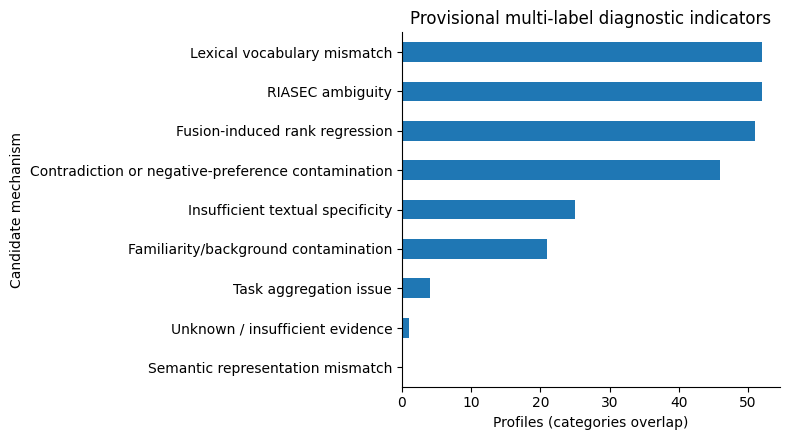

,profile_id,provisional_category,indicator,review_status
0,D001,Insufficient textual specificity,No predefined domain/task cues; primarily general preferences under this limited heuristic rubric.,unreviewed; multiple causes possible
1,D001,Lexical vocabulary mismatch,query coverage=0.079; BM25 rank=206.0,unreviewed; multiple causes possible
2,D001,Contradiction or negative-preference contamination,Negative/contradiction markers co-occur with a retrieval miss; not a causal ablation.,unreviewed; multiple causes possible
3,D001,Familiarity/background contamination,Provided plant/background metadata co-occurs with dense failure; genuine familiarity may be valid.,unreviewed; multiple causes possible
4,D001,RIASEC ambiguity,listed twins=7; score-band count=3,unreviewed; multiple causes possible
5,D001,Fusion-induced rank regression,M1 rank=22; fused rank=46,unreviewed; multiple causes possible
6,D002,Lexical vocabulary mismatch,query coverage=0.044; BM25 rank=210.0,unreviewed; multiple causes possible
7,D002,Contradiction or negative-preference contamination,Negative/contradiction markers co-occur with a retrieval miss; not a causal ablation.,unreviewed; multiple causes possible
8,D002,RIASEC ambiguity,listed twins=2; score-band count=2,unreviewed; multiple causes possible
9,D002,Fusion-induced rank regression,M1 rank=4; fused rank=52,unreviewed; multiple causes possible


**Semantic representation mismatch is unassigned:** no independent human semantic-relevance judgment is available. Zero assignments means insufficient evidence, not proof that the representation is adequate.

**Finding:** 252 overlapping provisional indicators cover 60 profiles; no definitive semantic-representation failures are assigned.

**Interpretation:** The taxonomy records reproducible observations and candidate explanations instead of forcing one cause per profile.

**Limitation:** Heuristic cue/metadata co-occurrence does not establish contamination or model failure. Category counts are not prevalence estimates of true causal failures.

**Next experiment:** Blindly review examples, then use one-variable ablations to separate vocabulary, evidence, aggregation and fusion mechanisms.

In [16]:
failure_records=[]
for row in diag.to_dict('records'):
    pid=row['profile_id']
    category,rationale=text_only_proposal(row['text'])
    indicators={
        'Insufficient textual specificity': (category=='broad',rationale),
        'Lexical vocabulary mismatch': (row['m3_query_coverage']<.1 or pd.isna(row['m3_target_rank']),f"query coverage={row['m3_query_coverage']:.3f}; BM25 rank={row['m3_target_rank']}"),
        'Task aggregation issue': (pd.notna(row['best_task_minus_aggregate']) and row['best_task_minus_aggregate']>=.15 and row['m4_target_rank']>10,f"best-task minus aggregate={row['best_task_minus_aggregate']:.3f}; dense rank={row['m4_target_rank']}"),
        'Contradiction or negative-preference contamination': ((row['has_contradiction'] or row['has_negative_cue']) and (row['m4_target_rank']>10 or pd.isna(row['m3_target_rank']) or row['m3_target_rank']>10),'Negative/contradiction markers co-occur with a retrieval miss; not a causal ablation.'),
        'Familiarity/background contamination': ((row['has_familiarity'] or row['background']) and row['m4_target_rank']>10,'Provided plant/background metadata co-occurs with dense failure; genuine familiarity may be valid.'),
        'RIASEC ambiguity': (row['has_twins'] or row['score_band_count']>=5,f"listed twins={row['riasec_twin_count']}; score-band count={row['score_band_count']}"),
        'Fusion-induced rank regression': (row['fusion_target_rank']>row['m1_target_rank'],f"M1 rank={row['m1_target_rank']}; fused rank={row['fusion_target_rank']}")}
    assigned=False
    for name,(flag,evidence) in indicators.items():
        if flag:
            failure_records.append({'profile_id':pid,'provisional_category':name,'indicator':evidence,'review_status':'unreviewed; multiple causes possible'})
            assigned=True
    if not assigned: failure_records.append({'profile_id':pid,'provisional_category':'Unknown / insufficient evidence','indicator':'No predefined indicator fired.','review_status':'unreviewed'})
failure_cases=pd.DataFrame(failure_records)
taxonomy_counts=failure_cases.groupby('provisional_category').profile_id.nunique()
taxonomy_counts.loc['Semantic representation mismatch']=0
taxonomy_counts.sort_values().plot.barh()
chart("Provisional multi-label diagnostic indicators", "Profiles (categories overlap)", "Candidate mechanism")
display(failure_cases.groupby('provisional_category').head(2))
display(Markdown('**Semantic representation mismatch is unassigned:** no independent human semantic-relevance judgment is available. Zero assignments means insufficient evidence, not proof that the representation is adequate.'))
conclude("D3", f"{len(failure_cases)} overlapping provisional indicators cover {failure_cases.profile_id.nunique()} profiles; no definitive semantic-representation failures are assigned.",
         "The taxonomy records reproducible observations and candidate explanations instead of forcing one cause per profile.",
         "Heuristic cue/metadata co-occurrence does not establish contamination or model failure. Category counts are not prevalence estimates of true causal failures.", "Blindly review examples, then use one-variable ablations to separate vocabulary, evidence, aggregation and fusion mechanisms.")

## D4 - Improvement priorities

**Research question:** Which next experiments have the best evidence and project value?

**Hypothesis:** Directly observed fusion loss and evidence-related indicators justify controlled tests before complex modeling.

**Data and methodology:** Rank proposals with an explicit exploratory rubric: 30% affected fraction, 20% observed median rank degradation (capped at100), 20% confidence, 10% inverse complexity, 20% contradiction/familiarity relevance. Confidence describes the observation, not causal certainty. No improvement is implemented.

,finding,supporting_evidence,affected_profiles,median_observed_fusion_rank_degradation,confidence_score_1_to_3,complexity_1_to_3,research_relevance_1_to_3,priority_score,suggested_experiment
0,Evidence selection with fixed RIASEC,Negative/contradictory/background material co-occurs with misses; task examples show positive si...,47,34.0,2,2,3,0.703000,"Compare raw user history with independently reviewed active-evidence selection, keeping tracker ..."
1,Blind specificity and benchmark audit,Human-verified specificity categories are absent; oracle and text channels expose different info...,18,27.5,3,2,3,0.611667,"Complete text-only human review before target reveal, then assess compatibility and family-level..."
2,Fixed fusion-weight ablation,Observed target-rank contributions directly explain loss of M1 top-five hits.,9,40.0,3,1,2,0.558333,Compare equal-weight RRF with one preregistered fixed structured-weight alternative on the same ...
3,Lexical query generic-term ablation,Actual tokenizer reveals broad high-frequency matches to target and competitor documents.,34,30.0,1,1,1,0.463333,"Change only one query term-selection rule; preserve BM25 documents, parameters and all nonlexica..."
4,Task aggregation ablation,High isolated task similarity can be diluted across sentence maxima; the mechanism is not causal...,4,44.0,1,2,1,0.308000,Keep text/model/index fixed and compare current max-task aggregation against one declared top-k-...


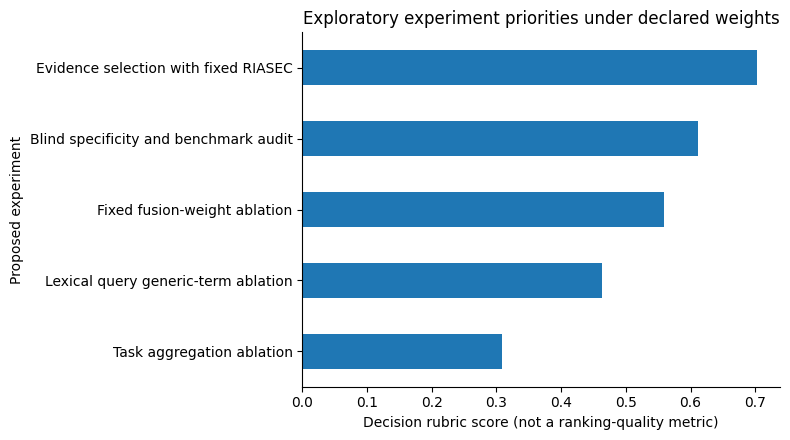

**Finding:** The top three rubric-ranked proposals are: Evidence selection with fixed RIASEC, Blind specificity and benchmark audit, Fixed fusion-weight ablation.

**Interpretation:** Priority combines observed affected cases with reviewable engineering/research judgments, rather than asserting that an untested change will improve accuracy.

**Limitation:** The weighting is a transparent planning heuristic. Overlapping affected groups and observational severity do not estimate causal treatment gains.

**Next experiment:** Preregister control/treatment and constants before implementing any selected experiment; retain all accepted baseline variants.

In [17]:
degradation=(diag.fusion_target_rank-diag.m1_target_rank).clip(lower=0)
candidate_specs=[
    ('Evidence selection with fixed RIASEC', (diag.has_negative_cue|diag.has_contradiction|diag.has_familiarity)&diag.m4_target_rank.gt(10),2,2,3,
     'Negative/contradictory/background material co-occurs with misses; task examples show positive similarity to dislikes.',
     'Compare raw user history with independently reviewed active-evidence selection, keeping tracker vector/model/aggregation/fusion fixed.'),
    ('Fixed fusion-weight ablation',fusion_cases.m1_success_fusion_failure.to_numpy(),3,1,2,
     'Observed target-rank contributions directly explain loss of M1 top-five hits.',
     'Compare equal-weight RRF with one preregistered fixed structured-weight alternative on the same saved component rankings.'),
    ('Blind specificity and benchmark audit',diag.profile_id.isin(sample_ids),3,2,3,
     'Human-verified specificity categories are absent; oracle and text channels expose different information.',
     'Complete text-only human review before target reveal, then assess compatibility and family-level ambiguity.'),
    ('Task aggregation ablation',diag.best_task_minus_aggregate.ge(.15)&diag.m4_target_rank.gt(10),1,2,1,
     'High isolated task similarity can be diluted across sentence maxima; the mechanism is not causally isolated.',
     'Keep text/model/index fixed and compare current max-task aggregation against one declared top-k-task alternative.'),
    ('Lexical query generic-term ablation',diag.m3_generic_matched_terms.ne('')&(diag.m3_target_rank.gt(10)|diag.m3_target_rank.isna()),1,1,1,
     'Actual tokenizer reveals broad high-frequency matches to target and competitor documents.',
     'Change only one query term-selection rule; preserve BM25 documents, parameters and all nonlexical signals.')]
priority_rows=[]
for name,mask,confidence,complexity,relevance,evidence,experiment in candidate_specs:
    mask=np.asarray(mask,dtype=bool)
    n=int(mask.sum())
    severity=float(degradation[mask].median()) if n else 0
    priority=.3*n/len(diag)+.2*min(severity/100,1)+.2*confidence/3+.1*(4-complexity)/3+.2*relevance/3
    priority_rows.append({'finding':name,'supporting_evidence':evidence,'affected_profiles':n,'median_observed_fusion_rank_degradation':severity,
                          'confidence_score_1_to_3':confidence,'complexity_1_to_3':complexity,'research_relevance_1_to_3':relevance,
                          'priority_score':priority,'suggested_experiment':experiment})
priorities=pd.DataFrame(priority_rows).sort_values('priority_score',ascending=False).reset_index(drop=True)
display(priorities)
priorities.set_index('finding').priority_score.sort_values().plot.barh()
chart("Exploratory experiment priorities under declared weights", "Decision rubric score (not a ranking-quality metric)", "Proposed experiment")
conclude("D4", f"The top three rubric-ranked proposals are: {', '.join(priorities.head(3).finding)}.",
         "Priority combines observed affected cases with reviewable engineering/research judgments, rather than asserting that an untested change will improve accuracy.",
         "The weighting is a transparent planning heuristic. Overlapping affected groups and observational severity do not estimate causal treatment gains.", "Preregister control/treatment and constants before implementing any selected experiment; retain all accepted baseline variants.")

## Final findings, limitations and next experiments

The following summary is generated from this execution. Diagnostic outputs are **not** appended to the experiment-history CSV. Human review is pending unless the preserved review table contains independently verified blind judgments. No M5 integration, model optimization, or scoring changes are performed.


In [18]:
# Add per-profile evaluator metrics to the consolidated diagnostic dataset.
for method in RUNS:
    indexed_metrics=metrics[metrics.method==method].set_index('profile_id')
    for metric in ('hit_at_5','ndcg_at_10'):
        diag[f'{method}_{metric}']=diag.profile_id.map(indexed_metrics[metric])
diag.to_csv(OUT/'profile_diagnostics.csv',index=False)
metrics.to_csv(OUT/'per_profile_metrics.csv',index=False)
subgroups.to_csv(OUT/'subgroup_metrics.csv',index=False)
fusion_cases.to_csv(OUT/'fusion_regressions.csv',index=False)
failure_cases.to_csv(OUT/'failure_cases.csv',index=False)
priorities.to_csv(OUT/'improvement_priorities.csv',index=False)
paired.to_csv(OUT/'paired_differences.csv',index=False)
distribution.to_csv(OUT/'riasec_distributions.csv')
sentence_matches.to_csv(OUT/'semantic_sentence_matches.csv',index=False)
five=[
    f"Oracle privilege and numerical ambiguity: median user-target cosine={diag.target_cosine.median():.3f}; M1 Hit@5={overview.loc['m1','hit_at_5']:.1%}; {int(diag.has_twins.sum())} profiles list RIASEC twins. Alignment does not identify a unique target.",
    f"Lexical coverage: {int(diag.m3_target_token_overlap.eq(0).sum())} targets have zero matched M3 query types; BM25 retrieves {int(diag.m3_target_rank.isna().sum())} targets at no positive score. Its Hit@5 is {overview.loc['m3','hit_at_5']:.1%}.",
    f"Semantic task versus aggregation: median best target-task similarity={diag.m4_target_task_similarity.median():.3f}, aggregate={diag.m4_target_score.median():.3f}; dense Hit@5={overview.loc['m4','hit_at_5']:.1%}. This does not isolate representation failure.",
    f"Fusion regression: three-way RRF loses {int(fusion_cases.m1_success_fusion_failure.sum())} M1 top-five successes and gains {int(fusion_cases.fusion_gain.sum())}; NDCG@10 changes by {overview.loc['fusion','ndcg_at_10']-overview.loc['m1','ndcg_at_10']:+.4f}.",
    f"Benchmark identifiability remains unverified: {len(annotations)} blind-stage provisional specificity annotations, {len(verified)} verified human reviews; no verified-specificity performance claim is made."]
summary=['# Ranking diagnostic findings','',f'Analyzed {len(diag)} development profiles, {len(occupation)} eligible occupations, and seven compatible saved M4 configurations. No held-out data was opened for diagnosis.','', '## Five consequential findings','']
summary += [f'{i+1}. {finding}' for i,finding in enumerate(five)]
summary += ['', '## Top three recommended experiments','']
summary += [f"{i+1}. **{row['finding']}**: {row['suggested_experiment']} (affected n={row['affected_profiles']}; planning score={row['priority_score']:.3f})." for i,row in priorities.head(3).iterrows()]
summary += ['', '## Section findings and limits','']
for item in findings:
    summary += [f"### {item['section']}",f"Finding: {item['finding']}",f"Interpretation: {item['interpretation']}",f"Limitation: {item['limitation']}",f"Next experiment: {item['next_experiment']}",'']
summary += ['## Integrity and limitations',json.dumps(integrity,sort_keys=True), semantic_status,
            'All annotations/taxonomies are provisional except explicitly supplied verified blind human reviews. Subgroup sizes are small, intervals exploratory, labels synthetic/O*NET-based, and correlations noncausal. Source configurations and metrics were not changed. No diagnostic calculations were registered as model experiments.']
(OUT/'findings_summary.md').write_text('\n'.join(summary),encoding='utf-8')
after=protected_fingerprints()
assert before==after, 'Protected datasets, code, existing reports or evaluation history changed during analysis.'
audit={'seed':SEED,'source_hashes':before,'integrity':integrity,'semantic_status':semantic_status,
       'blind_proposal_sha256':blind_hash,'verified_human_reviews':len(verified),'protected_files_unchanged':True,
       'helper_sha256':sha('notebooks/ranking_diagnostics.py'),'requirements_sha256':sha('requirements-diagnostics.txt'),
       'run_ids':{m:manifests[m]['run_id'] for m in RUNS},'no_history_rows_added':True}
from importlib.metadata import version
audit['analysis_versions']={name:version(name) for name in ('pandas','numpy','matplotlib','nbclient','nbformat','sentence-transformers','faiss-cpu')}
notebook_document=json.loads(Path('notebooks/ranking_diagnostic_analysis.ipynb').read_text(encoding='utf-8'))
audit['notebook_code_sha256']=hashlib.sha256(json.dumps([''.join(c['source']) for c in notebook_document['cells'] if c['cell_type']=='code']).encode()).hexdigest()
(OUT/'analysis_manifest.json').write_text(json.dumps(audit,indent=2,sort_keys=True)+'\n',encoding='utf-8')
display(Markdown('\n\n'.join(f'**{i+1}.** {finding}' for i,finding in enumerate(five))))
display(priorities.head(3)[['finding','affected_profiles','supporting_evidence','suggested_experiment']])
display(Markdown('**Read-only integrity verified:** protected datasets, production code, prior experiment artifacts and evaluation history are unchanged. Stop here; no new ranker or M5 work was performed.'))

**1.** Oracle privilege and numerical ambiguity: median user-target cosine=0.960; M1 Hit@5=16.7%; 29 profiles list RIASEC twins. Alignment does not identify a unique target.

**2.** Lexical coverage: 12 targets have zero matched M3 query types; BM25 retrieves 12 targets at no positive score. Its Hit@5 is 1.7%.

**3.** Semantic task versus aggregation: median best target-task similarity=0.353, aggregate=0.257; dense Hit@5=5.0%. This does not isolate representation failure.

**4.** Fusion regression: three-way RRF loses 9 M1 top-five successes and gains 2; NDCG@10 changes by -0.1350.

**5.** Benchmark identifiability remains unverified: 18 blind-stage provisional specificity annotations, 0 verified human reviews; no verified-specificity performance claim is made.

,finding,affected_profiles,supporting_evidence,suggested_experiment
0,Evidence selection with fixed RIASEC,47,Negative/contradictory/background material co-occurs with misses; task examples show positive si...,"Compare raw user history with independently reviewed active-evidence selection, keeping tracker ..."
1,Blind specificity and benchmark audit,18,Human-verified specificity categories are absent; oracle and text channels expose different info...,"Complete text-only human review before target reveal, then assess compatibility and family-level..."
2,Fixed fusion-weight ablation,9,Observed target-rank contributions directly explain loss of M1 top-five hits.,Compare equal-weight RRF with one preregistered fixed structured-weight alternative on the same ...


**Read-only integrity verified:** protected datasets, production code, prior experiment artifacts and evaluation history are unchanged. Stop here; no new ranker or M5 work was performed.